# **Projeto 2: alocação estável de alunos em projetos**

Universidade de Brasília, Departamento de Ciência da Computação

Teoria e Aplicação de Grafos, Turma 01, 2026/2, Prof. Díbio

| Integrante | Matrícula |
|---|---|
| Gabrielly Batista de Freitas | 251004400 |
| Helena Miranda Longo | 251004302 |

Este notebook contém o código, a descrição textual da variação do algoritmo de Gale-Shapley, as simulações de dez iterações nos dois sentidos (aluno propõe e projeto propõe), a matriz final de emparelhamentos e as verificações de estabilidade e de otimalidade. 

## README: o que foi feito e qual variação do algoritmo foi usada

### 1. O problema

Uma universidade oferece 50 projetos que somam 80 vagas, e 200 alunos se candidataram. Cada aluno indica até três projetos em ordem de preferência e tem uma nota agregada inteira em {3, 4, 5}. Cada projeto tem um número de vagas e uma nota mínima exigida. Queremos uma alocação estável, isto é, sem nenhum par aluno-projeto que prefira estar junto em vez de ficar com o que recebeu, e com o maior número possível de alunos alocados, porque quanto mais alunos alocados mais projetos conseguem ser realizados.

Esse é o problema de alocação de alunos a projetos (Student-Project Allocation, SPA) estudado por Abraham, Irving e Manlove (2007). O artigo propõe dois algoritmos, um orientado ao aluno (student-oriented), que devolve a alocação estável melhor para os alunos, e um orientado ao professor (lecturer-oriented), que devolve a alocação estável melhor para o lado dos projetos. No arquivo de entrada não há professores com limite próprio de carga, então cada projeto equivale ao único projeto de um orientador cujo limite é o próprio número de vagas. Com isso a camada dos professores não tem efeito e o problema fica igual ao problema de Hospitais e Residentes: alunos são os residentes e projetos são os hospitais, cada um com capacidade. Os dois algoritmos do artigo se reduzem, nesse caso, às duas versões clássicas do Gale-Shapley com capacidades.

### 2. Modelagem em grafos

Montamos um grafo bipartido em que um lado é o conjunto de alunos e o outro é o conjunto de projetos. Existe uma aresta (aluno, projeto) quando o aluno colocou o projeto na sua lista e a nota dele atinge o requisito do projeto. Pares barrados pela nota não viram aresta. Um emparelhamento é um conjunto de arestas em que cada aluno aparece no máximo uma vez e cada projeto aparece no máximo tantas vezes quanto suas vagas (um emparelhamento com capacidades).

A preferência dos alunos é a ordem que eles indicaram. O arquivo não traz preferência dos projetos, então ela é construída a partir da nota: nota maior é melhor. Como só existem três valores de nota, há muitos empates. Para rodar o Gale-Shapley precisamos de uma lista estrita, então os empates são desfeitos de forma determinística, sem sorteio: entre alunos de mesma nota vem primeiro quem colocou o projeto em posição melhor na sua lista, e se ainda assim empatar vem o menor código de aluno. Essa lista estrita é a Lista de Preferência do Projeto que aparece na matriz final. A parametrização `DESEMPATE` permite testar outras regras.

### 3. O que significa estável aqui

Um par (aluno a, projeto p) que não está no emparelhamento é um par bloqueante quando a prefere p ao projeto que recebeu (ou ficou sem nada) e p tem vaga livre ou prefere a a algum aluno que já recebeu. Um emparelhamento sem pares bloqueantes é estável. Usamos duas versões da definição.

Na estabilidade estrita, "p prefere a" significa estar à frente na lista estrita de p, incluindo o desempate. Na estabilidade fraca, p só prefere a quando a nota de a é estritamente maior que a de algum aluno de p. A segunda é a definição fiel aos dados, porque dois alunos com a mesma nota são equivalentes para o projeto e o desempate foi uma escolha nossa para poder rodar o algoritmo. Todo emparelhamento estável no sentido estrito também é estável no sentido fraco, mas não o contrário.

### 4. A variação do algoritmo (descrição pedida no enunciado)

**Pré-processamento.** Lemos o arquivo, descartamos preferências por projetos que não existem, descartamos repetições dentro da mesma lista e retiramos as arestas barradas pela nota mínima. Em seguida construímos a lista de cada projeto, ordenada por nota com o desempate descrito acima.

**Laço de 10 iterações.** Cada iteração tem duas fases, executadas sempre na mesma ordem e sem nenhum sorteio.

*Fase 1, uma rodada de aceitação adiada (Gale-Shapley com capacidades).* Existem duas versões e as duas são simuladas.
- Aluno propõe: cada aluno livre que ainda tem projeto não testado propõe ao próximo projeto da sua lista. Cada projeto junta as propostas novas com os alunos que já segurava, fica com os melhores até o limite de vagas (emparelhamento temporário) e rejeita o resto. Quem é rejeitado volta a ficar livre.
- Projeto propõe: cada projeto com vaga livre propõe aos próximos alunos da sua lista, um por vaga livre. Cada aluno junta as propostas recebidas com o projeto que já segurava, fica com o melhor segundo a sua própria ordem e rejeita os demais. A vaga do projeto rejeitado volta a ficar livre.

Em termos de caminhos alternados, uma proposta é uma aresta fora do emparelhamento e uma rejeição ou substituição é uma aresta do emparelhamento que sai. Quando um aluno livre propõe, desloca alguém, e o deslocado propõe em seguida, estamos percorrendo um caminho alternado que cresce um passo por iteração e que termina quando alguém encontra vaga livre (o emparelhamento aumenta em um) ou quando alguém esgota a lista. Por isso, a cada iteração, o ponto de partida são os alunos que ficaram sem emparelhamento na iteração anterior.

*Fase 2, caminhos alternados aumentantes que passam por empates.* Quando a fase 1 não tem mais propostas a fazer, o emparelhamento é estável no sentido estrito, mas ainda pode haver alunos livres que cabem se alguém de nota igual se mover para outro projeto. A fase 2 procura, a partir dos alunos livres, caminhos alternados que terminam em um projeto com vaga livre. A busca é em profundidade com aprofundamento iterativo, então o caminho mais curto é testado primeiro, e os alunos são percorridos em ordem de código, o que a torna determinística. Cada caminho candidato é aplicado em uma cópia do emparelhamento e só é aceito se a cópia respeitar as vagas e não tiver nenhum par bloqueante no sentido fraco. Assim o emparelhamento cresce sem perder a estabilidade. Cada iteração aceita no máximo um caminho, para que a evolução possa ser acompanhada passo a passo.

**Critério de parada.** O laço roda as 10 iterações pedidas. Ele fica estacionário quando uma iteração não tem propostas na fase 1 e nenhum caminho aumentante estável na fase 2. O programa avisa se isso não tiver acontecido até a décima iteração.

**Projetos sem alunos.** Todo projeto realizado precisa de pelo menos um aluno. Um projeto que termina com zero alunos é marcado como não realizado e o programa explica o motivo (sem candidato qualificado, ou candidatos que preferiram outros projetos).

**Resposta final.** Como pede o enunciado, a proposta final é a do lado do projeto (a lista de preferência do projeto conduz as propostas), seguida da fase 2. A versão em que o aluno propõe também é simulada e mostrada, e as duas são comparadas.

**Custo.** Na fase 1 cada aresta é proposta no máximo uma vez, então o custo total é linear no número de arestas. A fase 2 é uma busca com limite de comprimento (`MAXPASSOSCAMINHO`), porque encontrar o maior emparelhamento estável quando há empates é um problema difícil em geral.

### 5. Inconsistências no arquivo de entrada e o que fizemos

- Cinco alunos citam projetos que não existem: A2 (P51), A39 (P53), A51 (P52), A95 (P53) e A108 (P54). Essas preferências são ignoradas.
- Onze alunos repetem um projeto na própria lista (A63, A64, A67, A89, A118, A119, A133, A141, A163, A164 e A167). Vale a primeira ocorrência e a repetição é ignorada, então esses alunos ficam com menos de três opções.
- A linha de A177 não tem espaço entre ")" e "(5)". A leitura por expressão regular tolera isso.
- Trezentos pares aluno-projeto são barrados porque a nota do aluno é menor que o requisito do projeto. Eles não entram no grafo, mas aparecem na figura do grafo de entrada.
- A ordem de escolha mostrada na matriz final é a posição do projeto na lista original do aluno. Se o primeiro projeto de um aluno não existe, o segundo continua sendo contado como segunda escolha.

### 6. Como executar

No Jupyter, abra o notebook dentro da pasta `notebook` do projeto e use Run All: a entrada é lida de `../data/entradaProj2.26TAG.txt`. Se o arquivo estiver na pasta do notebook, ele também é encontrado. No Google Colab, execute a primeira célula de código e escolha o arquivo quando o botão de envio aparecer. Os parâmetros ficam na primeira célula de código: número de iterações, regra de desempate, limite do caminho aumentante e se os gráficos devem ser desenhados.

## **Etapa Inicial.** Configuração

Importamos as bibliotecas, definimos os parâmetros e as cores das arestas. As três cores pedidas no enunciado são azul para proposta ativa, verde para emparelhamento temporário e vermelho para rejeição. No Colab, se o arquivo de entrada não estiver na pasta de trabalho, a célula abre o seletor de arquivos.

In [1]:
import os, re, math, time
from collections import defaultdict, Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.collections import LineCollection
from matplotlib.colors import ListedColormap, BoundaryNorm
from IPython.display import display

# parâmetros do experimento
ARQUIVO = '../data/entradaProj2.26TAG.txt'   # estrutura do projeto: notebook/ e data/ lado a lado
NITERACOES = 10            # número de iterações do laço, fixado pelo enunciado
DESEMPATE = 'escolha'       # 'escolha', 'escassez' ou 'codigo' (ver etapa 2)
MAXPASSOSCAMINHO = 12     # número máximo de alunos em um caminho aumentante
MOSTRARGRAFICOS = True     # False acelera a execução se só os textos interessarem
LIMITELISTA = 40           # acima disso o log mostra só contagens e não cada proposta

# cores das arestas
CORPROPOSTA = '#1f77b4'    # azul: proposta ativa
CORTEMPORARIO = '#2ca02c'  # verde: emparelhamento temporário
CORREJEICAO = '#d62728'    # vermelho: rejeição
CORFUNDO = '#c8c8c8'       # cinza: aresta elegível ainda sem evento
CORBARRADA = '#ff9f1c'     # laranja: barrada pela nota mínima (só no grafo de entrada)

plt.rcParams['figure.dpi'] = 60
pd.set_option('display.max_rows', 300)
pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 200)
pd.set_option('display.max_colwidth', 90)

# localiza o arquivo de entrada: primeiro em ../data, depois na pasta do notebook
if not os.path.exists(ARQUIVO) and os.path.exists('entradaProj2.26TAG.txt'):
    ARQUIVO = 'entradaProj2.26TAG.txt'
if not os.path.exists(ARQUIVO):
    try:
        from google.colab import files
        print('Selecione o arquivo entradaProj2.26TAG.txt')
        enviados = files.upload()
        ARQUIVO = list(enviados.keys())[0]
    except ImportError:
        raise FileNotFoundError(f'Arquivo {ARQUIVO} não encontrado na pasta do notebook.')
print('Arquivo de entrada:', ARQUIVO)

Arquivo de entrada: ../data/entradaProj2.26TAG.txt


## **Etapa 1.** Leitura e limpeza dos dados

O arquivo tem duas seções. A primeira lista os projetos no formato (código, vagas, nota mínima) e a segunda lista os alunos no formato (código):(preferências) (nota). Usamos expressões regulares para ler, o que tolera espaços irregulares como o da linha de A177.

Depois da leitura, cada lista de preferências passa por três filtros, nesta ordem: projeto inexistente, projeto repetido na lista e nota abaixo do requisito. Tudo que for descartado é registrado em uma tabela de ocorrências, para que nada seja removido sem aparecer. Para cada aluno guardamos também a posição original de cada projeto elegível, porque a matriz final mostra a ordem de escolha como o aluno a escreveu.

In [2]:
def lerentrada(caminho):
    """Lê o arquivo e devolve dois dicionários: projetos e alunos."""
    texto = open(caminho, encoding='utf-8').read()
    projetos, alunos = {}, {}
    # (P12, 2, 5): código, vagas, nota mínima
    for m in re.finditer(r'\(P(\d+)\s*,\s*(\d+)\s*,\s*(\d+)\)', texto):
        projetos[int(m[1])] = {'vagas': int(m[2]), 'req': int(m[3])}
    # (A7):(P41, P31, P38) (4): código, preferências em ordem, nota
    for m in re.finditer(r'\(A(\d+)\)\s*:\s*\(([^)]*)\)\s*\((\d+)\)', texto):
        prefs = [int(x.strip().lstrip('Pp')) for x in m[2].split(',') if x.strip()]
        alunos[int(m[1])] = {'prefsoriginais': prefs, 'nota': int(m[3])}
    return projetos, alunos


def limparpreferencias(projetos, alunos):
    """Aplica os filtros de limpeza e devolve a tabela de ocorrências."""
    ocorrencias = []
    for a in sorted(alunos):
        d = alunos[a]
        vistos, elegiveis, escolha, validastodas, barradas = set(), [], {}, [], []
        for pos, p in enumerate(d['prefsoriginais'], start=1):
            if p not in projetos:
                ocorrencias.append((f'A{a}', 'projeto inexistente', f'P{p}'))
                continue
            if p in vistos:
                ocorrencias.append((f'A{a}', 'projeto repetido na lista', f'P{p}'))
                continue
            vistos.add(p)
            validastodas.append(p)
            if d['nota'] < projetos[p]['req']:
                ocorrencias.append((f'A{a}', 'nota abaixo do requisito',
                                    f"P{p} (nota {d['nota']}, exige {projetos[p]['req']})"))
                barradas.append(p)
                continue
            elegiveis.append(p)
            escolha[p] = pos          # posição na lista original do aluno
        d['prefs'] = elegiveis        # projetos elegíveis, na ordem do aluno
        d['escolha'] = escolha
        d['validastodas'] = validastodas
        d['barradas'] = barradas
    return pd.DataFrame(ocorrencias, columns=['Aluno', 'Ocorrência', 'Detalhe'])


projetos, alunos = lerentrada(ARQUIVO)
dfocorrencias = limparpreferencias(projetos, alunos)

print(f'Projetos lidos: {len(projetos)}   Alunos lidos: {len(alunos)}')
print(f"Total de vagas: {sum(d['vagas'] for d in projetos.values())}")
print('Distribuição das notas dos alunos:', dict(sorted(Counter(d['nota'] for d in alunos.values()).items())))
print('Distribuição dos requisitos dos projetos:', dict(sorted(Counter(d['req'] for d in projetos.values()).items())))
print()
print('Ocorrências encontradas na limpeza:')
print(dfocorrencias['Ocorrência'].value_counts().to_string())
print()
display(dfocorrencias[dfocorrencias['Ocorrência'] != 'nota abaixo do requisito'])
nsemopcao = sum(1 for d in alunos.values() if not d['prefs'])
print(f'Alunos sem nenhuma opção elegível (todas barradas ou inexistentes): {nsemopcao}')
print(f"Alunos com pelo menos uma opção elegível: {len(alunos) - nsemopcao}")

Projetos lidos: 50   Alunos lidos: 200
Total de vagas: 80
Distribuição das notas dos alunos: {3: 69, 4: 98, 5: 33}
Distribuição dos requisitos dos projetos: {3: 3, 4: 26, 5: 21}

Ocorrências encontradas na limpeza:
Ocorrência
nota abaixo do requisito     300
projeto repetido na lista     11
projeto inexistente            5



,Aluno,Ocorrência,Detalhe
0,A2,projeto inexistente,P51
61,A39,projeto inexistente,P53
76,A51,projeto inexistente,P52
91,A63,projeto repetido na lista,P39
92,A64,projeto repetido na lista,P30
97,A67,projeto repetido na lista,P31
138,A89,projeto repetido na lista,P19
146,A95,projeto inexistente,P53
165,A108,projeto inexistente,P54
186,A118,projeto repetido na lista,P28


Alunos sem nenhuma opção elegível (todas barradas ou inexistentes): 66
Alunos com pelo menos uma opção elegível: 134


## **Etapa 2.** Grafo bipartido e listas de preferência dos projetos

A classe `Instancia` reúne tudo que o algoritmo consulta: vagas, notas, listas elegíveis dos alunos e a lista de preferência de cada projeto, já ordenada. Para cada projeto, os candidatos são os alunos com aresta nele, e a lista é ordenada por nota decrescente com desempate determinístico. Há três regras de desempate disponíveis:

- `escolha` (padrão): entre alunos de mesma nota vem primeiro quem colocou o projeto em posição melhor, depois o menor código. Premia o interesse declarado.
- `escassez`: entre alunos de mesma nota vem primeiro quem tem menos opções elegíveis, depois a posição de escolha, depois o código. Favorece quem tem menos alternativas.
- `codigo`: desempata só pelo código do aluno.

`pos[p][a]` guarda a posição do aluno a na lista do projeto p (1 é o melhor). Esse número é o "Top k de n alunos na lista" da matriz final.

A figura em seguida mostra o grafo bipartido de entrada. As arestas cinzas são as elegíveis e as laranjas tracejadas são as barradas pela nota mínima. Alunos sem nenhuma aresta elegível aparecem em cinza claro.

In [3]:
class Instancia:
    """Dados do problema depois da limpeza, prontos para o algoritmo."""
    def __init__(self, projetos, alunos, desempate='escolha'):
        self.projetos, self.alunos = projetos, alunos
        self.vagas = {p: d['vagas'] for p, d in projetos.items()}
        self.req = {p: d['req'] for p, d in projetos.items()}
        self.nota = {a: d['nota'] for a, d in alunos.items()}
        self.prefs = {a: d['prefs'] for a, d in alunos.items()}
        self.escolha = {a: d['escolha'] for a, d in alunos.items()}
        self.elegiveis = [a for a in sorted(alunos) if alunos[a]['prefs']]
        # candidatos de cada projeto: alunos com aresta elegível
        self.cand = {p: [] for p in projetos}
        for a in sorted(alunos):
            for p in self.prefs[a]:
                self.cand[p].append(a)
        chaves = {
            'escolha':  lambda a, p: (-self.nota[a], self.escolha[a][p], a),
            'escassez': lambda a, p: (-self.nota[a], len(self.prefs[a]), self.escolha[a][p], a),
            'codigo':   lambda a, p: (-self.nota[a], a),
        }
        chave = chaves[desempate]
        # lista de preferência estrita de cada projeto
        self.lista = {p: sorted(self.cand[p], key=lambda a, p=p: chave(a, p)) for p in projetos}
        self.pos = {p: {a: i for i, a in enumerate(self.lista[p], start=1)} for p in projetos}


I = Instancia(projetos, alunos, DESEMPATE)
narestas = sum(len(v) for v in I.prefs.values())
print(f'Regra de desempate: {DESEMPATE}')
print(f'Arestas elegíveis no grafo bipartido: {narestas}')
for p in (20, 30, 28):
    topo = ', '.join(f'A{a}(nota {I.nota[a]})' for a in I.lista[p][:6])
    print(f'Lista de P{p} ({I.vagas[p]} vagas, exige {I.req[p]}, {len(I.lista[p])} candidatos), primeiros 6: {topo}')

Regra de desempate: escolha
Arestas elegíveis no grafo bipartido: 280
Lista de P20 (1 vagas, exige 4, 15 candidatos), primeiros 6: A32(nota 5), A64(nota 5), A100(nota 5), A200(nota 5), A24(nota 4), A41(nota 4)
Lista de P30 (1 vagas, exige 4, 16 candidatos), primeiros 6: A64(nota 5), A1(nota 5), A2(nota 5), A33(nota 5), A83(nota 5), A66(nota 4)
Lista de P28 (1 vagas, exige 3, 14 candidatos), primeiros 6: A127(nota 5), A18(nota 5), A137(nota 5), A48(nota 4), A58(nota 4), A148(nota 4)


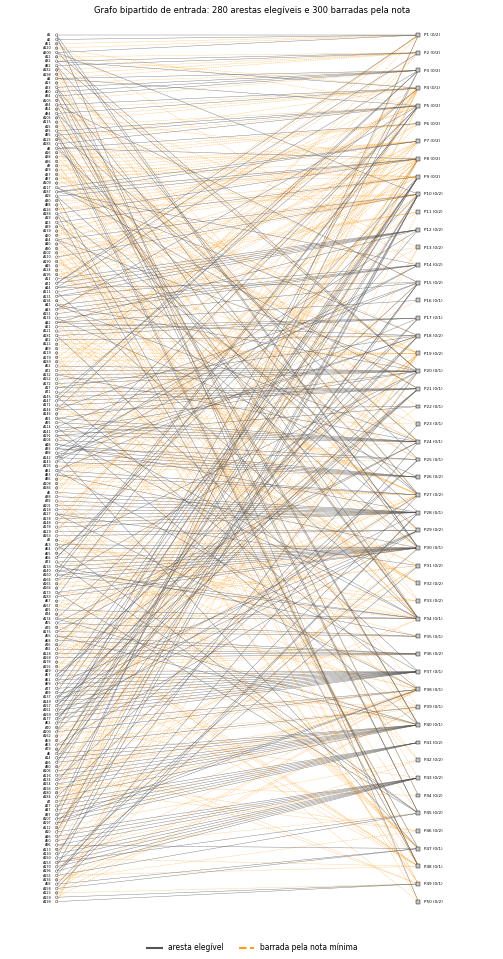

In [4]:
# funções de desenho (usadas aqui e nas simulações)
def layoutbipartido(I, alunosexibidos):
    """Alunos na coluna x=0 e projetos na coluna x=1. A ordem dos alunos segue o
    primeiro projeto da lista, o que reduz o cruzamento de arestas."""
    def chave(a):
        base = I.prefs[a] or I.alunos[a]['validastodas']
        return (base[0] if base else 999, a)
    ordem = sorted(alunosexibidos, key=chave)
    ys = {a: 1 - i / max(len(ordem) - 1, 1) for i, a in enumerate(ordem)}
    ps = sorted(I.projetos)
    yp = {p: 1 - i / (len(ps) - 1) for i, p in enumerate(ps)}
    return ys, yp


def desenharpainel(ax, I, ys, yp, par, camadas, titulo, rotulos=True):
    """Desenha um painel do grafo bipartido. 'camadas' é uma lista de
    (arestas, cor, espessura, transparência, estilo) desenhadas nessa ordem."""
    for arestas, cor, lw, alpha, estilo in camadas:
        segs = [[(0, ys[a]), (1, yp[p])] for a, p in arestas if a in ys]
        if segs:
            ax.add_collection(LineCollection(segs, colors=cor, linewidths=lw, alpha=alpha, linestyles=estilo))
    ocup = Counter(par.values())
    # alunos: verde = emparelhado, branco = livre com opções, cinza = sem opção elegível
    coresa = [CORTEMPORARIO if a in par else ('white' if I.prefs[a] else CORFUNDO) for a in ys]
    ax.scatter([0] * len(ys), list(ys.values()), s=9, c=coresa, edgecolors='black', linewidths=0.4, zorder=3)
    # projetos: verde = tem pelo menos um aluno, cinza = vazio
    coresp = [CORTEMPORARIO if ocup[p] > 0 else CORFUNDO for p in yp]
    ax.scatter([1] * len(yp), list(yp.values()), s=22, c=coresp, marker='s', edgecolors='black', linewidths=0.5, zorder=3)
    if rotulos:
        for a, y in ys.items():
            ax.text(-0.015, y, f'A{a}', ha='right', va='center', fontsize=4)
        for p, y in yp.items():
            ax.text(1.015, y, f'P{p} ({ocup[p]}/{I.vagas[p]})', ha='left', va='center', fontsize=5)
    ax.set_xlim(-0.14, 1.22)
    ax.set_ylim(-0.02, 1.02)
    ax.set_title(titulo, fontsize=10)
    ax.axis('off')


def legenda(fig, itens, ncol):
    fig.legend(handles=[Line2D([0], [0], color=c, lw=2.5, ls=ls, label=r) for r, c, ls in itens],
               loc='lower center', ncol=ncol, fontsize=9, frameon=False)


def desenharentrada(I):
    """Grafo bipartido de entrada: arestas elegíveis e arestas barradas pela nota."""
    todos = sorted(I.alunos)
    ys, yp = layoutbipartido(I, todos)
    elegiveis = [(a, p) for a in todos for p in I.prefs[a]]
    barradas = [(a, p) for a in todos for p in I.alunos[a]['barradas']]
    fig, ax = plt.subplots(figsize=(8.5, 16))
    desenharpainel(ax, I, ys, yp, {}, [(barradas, CORBARRADA, 0.5, 0.7, 'dashed'),
                                        (elegiveis, '#555555', 0.5, 0.8, 'solid')],
                    f'Grafo bipartido de entrada: {len(elegiveis)} arestas elegíveis e {len(barradas)} barradas pela nota')
    legenda(fig, [('aresta elegível', '#555555', '-'), ('barrada pela nota mínima', CORBARRADA, '--')], 2)
    plt.tight_layout(rect=(0, 0.03, 1, 1))
    plt.show()


if MOSTRARGRAFICOS:
    desenharentrada(I)

## **Etapa 3.** Índice de preferência por projeto

O índice mede o quanto cada projeto é desejado pelos alunos que poderiam ocupá-lo. Para cada projeto contamos quantos candidatos qualificados o colocaram em primeira, segunda e terceira escolha (n1, n2 e n3) e calculamos

índice = (3·n1 + 2·n2 + 1·n3) / vagas

Quanto maior o índice, mais concorrido é o projeto em relação às vagas que oferece. Um índice abaixo de 1 indica que mesmo que todos os interessados fossem colocados haveria folga de vagas, e um projeto com índice zero não tem candidato qualificado e não poderá ser realizado. A tabela também mostra os interessados totais (incluindo os barrados pela nota), para separar falta de interesse de falta de qualificação.

,Projeto,Vagas,Nota mín.,Interessados,Barrados pela nota,Qualificados,1ª,2ª,3ª,Índice de preferência
0,P37,1,3,14,0,14,12,0,2,38.0
1,P30,1,4,24,8,16,6,9,1,37.0
2,P40,1,4,22,8,14,3,8,3,28.0
3,P20,1,4,18,3,15,0,12,3,27.0
4,P21,1,4,13,3,10,2,8,0,22.0
5,P24,1,4,18,7,11,4,0,7,19.0
6,P28,1,3,14,0,14,2,1,11,19.0
7,P34,1,4,23,13,10,1,4,5,16.0
8,P17,1,3,6,0,6,0,6,0,12.0
9,P43,2,4,12,3,9,4,5,0,11.0


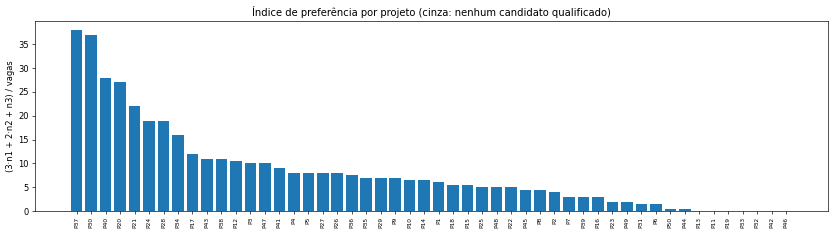

In [5]:
def indicepreferencia(I):
    linhas = []
    for p in sorted(I.projetos):
        n = [0, 0, 0]
        for a in I.cand[p]:
            n[I.escolha[a][p] - 1] += 1
        interessados = sum(1 for a in I.alunos if p in I.alunos[a]['validastodas'])
        indice = (3 * n[0] + 2 * n[1] + 1 * n[2]) / I.vagas[p]
        linhas.append({'Projeto': f'P{p}', 'Vagas': I.vagas[p], 'Nota mín.': I.req[p],
                       'Interessados': interessados, 'Barrados pela nota': interessados - len(I.cand[p]),
                       'Qualificados': len(I.cand[p]), '1ª': n[0], '2ª': n[1], '3ª': n[2],
                       'Índice de preferência': round(indice, 2)})
    return pd.DataFrame(linhas)


dfindice = indicepreferencia(I)
display(dfindice.sort_values('Índice de preferência', ascending=False).reset_index(drop=True))

if MOSTRARGRAFICOS:
    ordenado = dfindice.sort_values('Índice de preferência', ascending=False)
    cores = [CORPROPOSTA if v > 0 else CORFUNDO for v in ordenado['Índice de preferência']]
    fig, ax = plt.subplots(figsize=(14, 4))
    ax.bar(ordenado['Projeto'], ordenado['Índice de preferência'], color=cores)
    ax.set_title('Índice de preferência por projeto (cinza: nenhum candidato qualificado)')
    ax.set_ylabel('(3·n1 + 2·n2 + n3) / vagas')
    plt.xticks(rotation=90, fontsize=7)
    plt.tight_layout()
    plt.show()

## **Etapa 4.** O motor do algoritmo

Aqui estão as peças da variação descrita no README.

`paresbloqueantes` testa a estabilidade, estrita ou fraca. `rodadaalunopropoe` e `rodadaprojetopropoe` executam a fase 1, uma rodada síncrona de aceitação adiada em cada sentido. Todas as decisões de uma rodada são tomadas sobre o estado do início da rodada, o que torna o resultado independente de qualquer ordem de execução. `tentaraumentar` executa a fase 2, a busca de caminho alternado aumentante que preserva a estabilidade fraca.

Um caminho aumentante começa em um aluno livre s0, que entra em um projeto p1 cheio, deslocando um aluno s1, que passa para um projeto p2, e assim por diante, até que o último aluno da cadeia entra em um projeto com vaga livre. Os alunos da cadeia trocam de projeto e um aluno livre passa a estar emparelhado, então o tamanho do emparelhamento sobe em um. A busca usa aprofundamento iterativo, tentando primeiro caminhos com um aluno, depois com dois, e assim até `MAXPASSOSCAMINHO`. Por isso o primeiro caminho aceito é sempre um dos mais curtos.

In [6]:
def ocupantes(par):
    """Inverte o emparelhamento: projeto -> lista de alunos."""
    ocup = defaultdict(list)
    for a, p in par.items():
        ocup[p].append(a)
    return ocup


def paresbloqueantes(I, par, fraca=False):
    """Lista os pares (aluno, projeto) que bloqueiam o emparelhamento 'par'.
    fraca=False: o projeto prefere o aluno se ele está à frente na lista estrita.
    fraca=True: o projeto só prefere o aluno se a nota dele é estritamente maior
    que a de algum aluno já alocado (empate de nota não bloqueia)."""
    ocup = ocupantes(par)
    bloq = []
    for a in sorted(I.alunos):
        atual = I.escolha[a][par[a]] if a in par else math.inf
        for p in I.prefs[a]:
            if I.escolha[a][p] >= atual:      # o aluno não prefere p ao que tem
                continue
            if len(ocup[p]) < I.vagas[p]:     # vaga livre: bloqueia
                bloq.append((a, p))
                continue
            if fraca:
                if I.nota[a] > min(I.nota[x] for x in ocup[p]):
                    bloq.append((a, p))
            else:
                pior = max(ocup[p], key=lambda x: I.pos[p][x])
                if I.pos[p][a] < I.pos[p][pior]:
                    bloq.append((a, p))
    return bloq


def rodadaalunopropoe(I, par, prox):
    """Fase 1, versão em que o aluno propõe. 'prox[a]' é o índice da próxima
    proposta do aluno a. Devolve as propostas e as rejeições da rodada."""
    livres = [a for a in I.elegiveis if a not in par and prox[a] < len(I.prefs[a])]
    propostas, porprojeto = [], defaultdict(list)
    for a in livres:                           # ordem de código: determinístico
        p = I.prefs[a][prox[a]]
        prox[a] += 1
        propostas.append((a, p))
        porprojeto[p].append(a)
    rejeicoes = []
    for p in sorted(porprojeto):
        seguros = [a for a, q in par.items() if q == p]
        todos = sorted(seguros + porprojeto[p], key=lambda a: I.pos[p][a])
        for a in todos[I.vagas[p]:]:           # excedem as vagas: rejeitados
            rejeicoes.append((a, p))
            par.pop(a, None)
        for a in todos[:I.vagas[p]]:           # melhores: emparelhamento temporário
            par[a] = p
    return propostas, rejeicoes


def rodadaprojetopropoe(I, par, prox):
    """Fase 1, versão em que o projeto propõe. 'prox[p]' é o índice do próximo
    aluno da lista do projeto p que ainda não recebeu proposta dele."""
    ocup = Counter(par.values())
    propostas, poraluno = [], defaultdict(list)
    for p in sorted(I.projetos):
        livres = I.vagas[p] - ocup[p]
        while livres > 0 and prox[p] < len(I.lista[p]):
            a = I.lista[p][prox[p]]
            prox[p] += 1
            livres -= 1
            propostas.append((a, p))
            poraluno[a].append(p)
    rejeicoes = []
    for a in sorted(poraluno):
        opcoes = poraluno[a] + ([par[a]] if a in par else [])
        melhor = min(opcoes, key=lambda p: I.escolha[a][p])   # a ordem do aluno decide
        for p in opcoes:
            if p != melhor:
                rejeicoes.append((a, p))
        par[a] = melhor
    return propostas, rejeicoes


def tentaraumentar(I, par, origens, maxpassos=MAXPASSOSCAMINHO):
    """Fase 2. Procura um caminho alternado aumentante a partir dos alunos livres.
    Se achar um que mantém a estabilidade fraca, aplica em 'par' e o devolve."""
    ocup = ocupantes(par)
    origens = [a for a in origens if I.prefs[a]]

    def gerar(a, visitados, restante, trilha):
        # gera as trilhas em que a entra em um projeto p; se p está cheio, algum
        # ocupante b sai de p e continua a trilha; se p tem vaga, a trilha acaba
        for p in I.prefs[a]:
            if par.get(a) == p:
                continue
            if len(ocup[p]) < I.vagas[p]:
                if restante == 1:
                    yield trilha + [(a, p)]
            elif restante > 1:
                for b in sorted(ocup[p]):
                    if b not in visitados:
                        yield from gerar(b, visitados | {b}, restante - 1, trilha + [(a, p)])

    for k in range(1, maxpassos + 1):        # aprofundamento iterativo
        for s in origens:
            for trilha in gerar(s, {s}, k, []):
                novo = dict(par)
                for a, p in trilha:
                    novo[a] = p
                cont = Counter(novo.values())
                if any(cont[p] > I.vagas[p] for p in cont):
                    continue                    # estourou a capacidade de algum projeto
                if paresbloqueantes(I, novo, fraca=True):
                    continue                    # criaria par bloqueante
                removidas = [(a, par[a]) for a, p in trilha if a in par]
                par.clear()
                par.update(novo)
                return {'caminho': trilha, 'novas': trilha, 'removidas': removidas}
    return {'caminho': None, 'novas': [], 'removidas': []}


def maxcardinalidade(I):
    """Maior emparelhamento possível ignorando a estabilidade (limite superior).
    Algoritmo de caminhos aumentantes com capacidades."""
    par, vagasocupadas = {}, defaultdict(list)
    def tenta(a, vistos):
        for p in I.prefs[a]:
            if p in vistos:
                continue
            vistos.add(p)
            if len(vagasocupadas[p]) < I.vagas[p]:
                vagasocupadas[p].append(a); par[a] = p
                return True
            for b in list(vagasocupadas[p]):
                if tenta(b, vistos):
                    vagasocupadas[p].remove(b); vagasocupadas[p].append(a); par[a] = p
                    return True
        return False
    for a in I.elegiveis:
        tenta(a, set())
    return par

## **Etapa 5.** Laço de iterações, log e visualização

`simular` roda o laço de `NITERACOES` iterações. Em cada uma:

1. A fase 1 executa uma rodada de propostas. Os alunos de partida são os que ficaram livres na iteração anterior (no modo aluno propõe) ou os projetos com vaga livre (no modo projeto propõe).
2. Se a fase 1 não teve nenhuma proposta, o emparelhamento já é estável e a fase 2 tenta aumentá-lo com um caminho alternado a partir dos alunos que continuam livres.
3. O estado da iteração é guardado: propostas ativas, rejeições, emparelhamento temporário e o caminho aumentante, se houve.

A figura de cada iteração tem dois painéis. O da esquerda mostra as propostas ativas da iteração em azul sobre o grafo cinza. O da direita mostra o resultado: arestas verdes do emparelhamento temporário, arestas vermelhas fortes das rejeições desta iteração e arestas vermelhas apagadas das rejeições de iterações anteriores. Os nós dos alunos são verdes quando emparelhados, brancos quando livres com opções, e cinza quando não têm opção elegível. Os nós dos projetos mostram ocupadas/vagas.

In [7]:
def simular(I, modo, niter=NITERACOES):
    """Roda o laço de niter iterações. modo = 'aluno' ou 'projeto'."""
    par = {}
    prox = {a: 0 for a in I.elegiveis} if modo == 'aluno' else {p: 0 for p in I.projetos}
    historico, rejacum = [], set()
    tamda, parda = None, None
    for t in range(1, niter + 1):
        livresini = [a for a in I.elegiveis if a not in par]
        if modo == 'aluno':
            props, rejs = rodadaalunopropoe(I, par, prox)
        else:
            props, rejs = rodadaprojetopropoe(I, par, prox)
        fase2, tamantes = None, len(par)
        if not props:                         # fase 1 esgotada: tenta aumentar
            if tamda is None:
                tamda, parda = len(par), dict(par)
            fase2 = tentaraumentar(I, par, livresini)
        novas = fase2['novas'] if fase2 else []
        removidas = fase2['removidas'] if fase2 else []
        rejacum |= set(rejs) | set(removidas)
        rejacum -= set(par.items())          # aresta que voltou a ser emparelhada deixa de ser rejeição
        historico.append({
            't': t, 'livresini': livresini, 'props': props, 'rejs': rejs, 'fase2': fase2,
            'ativas': props + novas, 'rejeitadas': rejs + removidas,
            'par': dict(par), 'rejacum': set(rejacum), 'tam': len(par), 'tam_antes_fase2': tamantes})
    ultimo = historico[-1]
    convergiu = (not ultimo['props']) and ultimo['fase2'] is not None and ultimo['fase2']['caminho'] is None
    return {'modo': modo, 'historico': historico, 'par': par, 'convergiu': convergiu,
            'tamda': tamda, 'parda': parda}


def mostrarlog(I, rec, modo):
    """Imprime o resumo textual de uma iteração."""
    t, par = rec['t'], rec['par']
    print(f"Iteração {t}")
    print(f"  Alunos livres no início da iteração: {len(rec['livresini'])}")
    aceitas = [e for e in rec['props'] if par.get(e[0]) == e[1]]
    print(f"  Fase 1: propostas ativas {len(rec['props'])}, emparelhamentos temporários novos {len(aceitas)}, rejeições {len(rec['rejs'])}")
    if 0 < len(rec['props']) <= LIMITELISTA:
        if modo == 'aluno':
            print('    Propostas: ' + '; '.join(f'A{a} propôs a P{p}' for a, p in rec['props']))
        else:
            print('    Propostas: ' + '; '.join(f'P{p} propôs a A{a}' for a, p in rec['props']))
    if 0 < len(rec['rejs']) <= LIMITELISTA:
        print('    Rejeições: ' + '; '.join(f'A{a} e P{p}' for a, p in rec['rejs']))
    f2 = rec['fase2']
    if f2 is None:
        print('  Fase 2: não executada, a fase 1 ainda tinha propostas a fazer')
    elif f2['caminho'] is None:
        print(f"  Fase 2: nenhum caminho aumentante estável a partir dos {len(rec['livresini'])} alunos livres")
    else:
        antigos = dict(f2['removidas'])
        passos = []
        for a, p in f2['caminho']:
            passos.append(f'A{a} entra em P{p}' if a not in antigos else f'A{a} sai de P{antigos[a]} e entra em P{p}')
        print(f"  Fase 2: caminho aumentante com {len(f2['caminho'])} alunos: " + '; '.join(passos))
    nproj = len(set(par.values()))
    print(f"  Ao final da iteração: {rec['tam']} alunos emparelhados em {nproj} projetos")


def desenhariteracao(I, rec, modo):
    """Duas vistas da iteração: propostas ativas e estado ao final."""
    ys, yp = layoutbipartido(I, I.elegiveis)
    todas = [(a, p) for a in I.elegiveis for p in I.prefs[a]]
    par = rec['par']
    temporarias = list(par.items())
    rejagora = [e for e in rec['rejeitadas'] if e not in par.items()]
    rejantes = [e for e in rec['rejacum'] if e not in set(rec['rejeitadas'])]
    nome = 'aluno propõe' if modo == 'aluno' else 'projeto propõe'
    fig, axs = plt.subplots(1, 2, figsize=(14, 12.5))
    desenharpainel(axs[0], I, ys, yp, par,
                    [(todas, CORFUNDO, 0.3, 0.6, 'solid'), (rec['ativas'], CORPROPOSTA, 1.8, 1.0, 'solid')],
                    f"Iteração {rec['t']} ({nome}): propostas ativas ({len(rec['ativas'])})")
    desenharpainel(axs[1], I, ys, yp, par,
                    [(todas, CORFUNDO, 0.3, 0.5, 'solid'), (rejantes, CORREJEICAO, 0.5, 0.3, 'solid'),
                     (rejagora, CORREJEICAO, 1.0, 0.9, 'solid'), (temporarias, CORTEMPORARIO, 1.6, 1.0, 'solid')],
                    f"Estado ao final da iteração {rec['t']}: {rec['tam']} alunos emparelhados")
    legenda(fig, [('proposta ativa', CORPROPOSTA, '-'), ('emparelhamento temporário', CORTEMPORARIO, '-'),
                  ('rejeição', CORREJEICAO, '-'), ('aresta elegível sem evento', CORFUNDO, '-')], 4)
    plt.tight_layout(rect=(0, 0.025, 1, 1))
    plt.show()


def executaremostrar(I, modo):
    res = simular(I, modo)
    for rec in res['historico']:
        mostrarlog(I, rec, modo)
        if MOSTRARGRAFICOS:
            desenhariteracao(I, rec, modo)
        print()
    return res


def tabelaevolucao(res):
    linhas = []
    for rec in res['historico']:
        f2 = rec['fase2']
        linhas.append({'Iteração': rec['t'], 'Propostas': len(rec['props']),
                       'Rejeições': len(rec['rejs']),
                       'Caminho aumentante (alunos)': len(f2['caminho']) if f2 and f2['caminho'] else 0,
                       'Alunos emparelhados': rec['tam'],
                       'Projetos com aluno': len(set(rec['par'].values()))})
    return pd.DataFrame(linhas)

## **Etapa 6.** Simulação A: o aluno propõe

Esta é a versão orientada ao aluno (student-oriented). Ela devolve, na fase 1, a alocação estável mais favorável aos alunos: nenhum aluno consegue um projeto melhor em qualquer outra alocação estável. Em seguida a fase 2 tenta aumentar o emparelhamento pelos caminhos alternados.

Iteração 1
  Alunos livres no início da iteração: 134
  Fase 1: propostas ativas 134, emparelhamentos temporários novos 53, rejeições 81
  Fase 2: não executada, a fase 1 ainda tinha propostas a fazer
  Ao final da iteração: 53 alunos emparelhados em 38 projetos


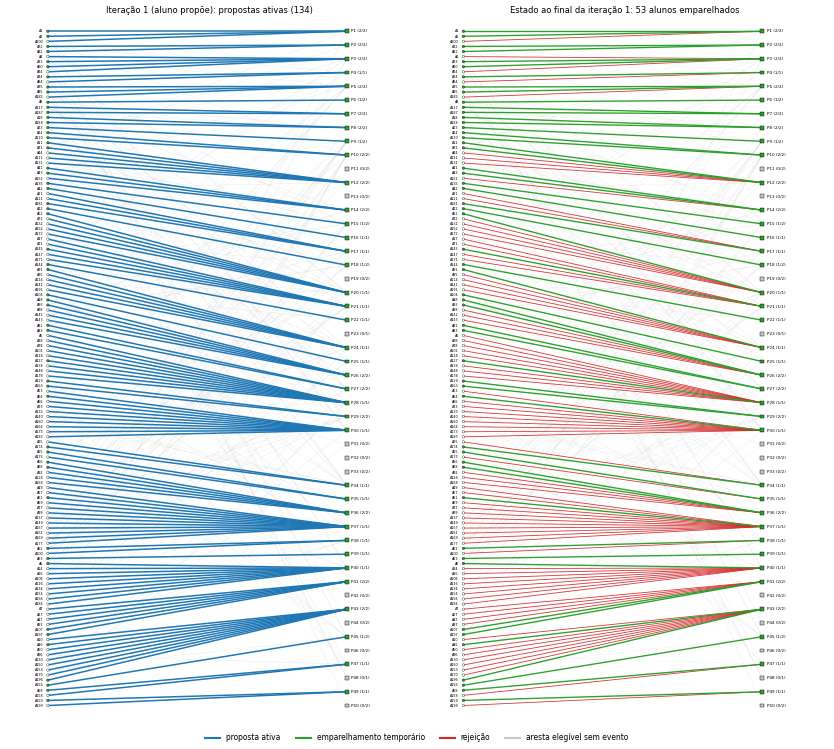


Iteração 2
  Alunos livres no início da iteração: 81
  Fase 1: propostas ativas 53, emparelhamentos temporários novos 8, rejeições 49
  Fase 2: não executada, a fase 1 ainda tinha propostas a fazer
  Ao final da iteração: 57 alunos emparelhados em 38 projetos


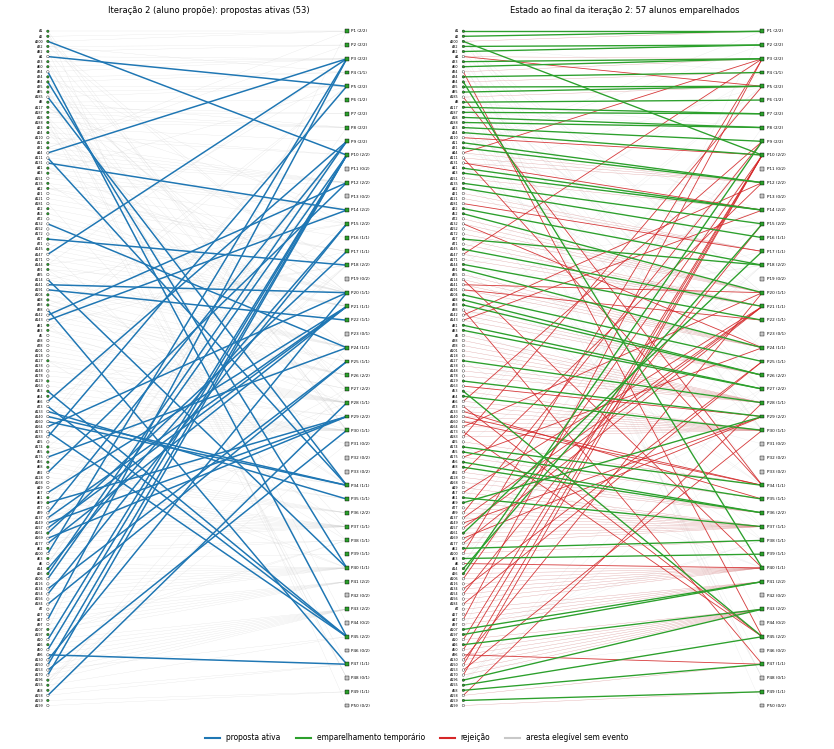


Iteração 3
  Alunos livres no início da iteração: 77
  Fase 1: propostas ativas 19, emparelhamentos temporários novos 4, rejeições 19
    Propostas: A6 propôs a P9; A44 propôs a P15; A57 propôs a P18; A66 propôs a P10; A98 propôs a P18; A100 propôs a P20; A114 propôs a P15; A137 propôs a P28; A140 propôs a P5; A142 propôs a P18; A143 propôs a P5; A149 propôs a P9; A153 propôs a P45; A157 propôs a P18; A160 propôs a P5; A169 propôs a P9; A177 propôs a P18; A181 propôs a P37; A191 propôs a P34
    Rejeições: A140 e P5; A143 e P5; A160 e P5; A26 e P9; A149 e P9; A169 e P9; A66 e P10; A44 e P15; A114 e P15; A22 e P18; A17 e P18; A57 e P18; A98 e P18; A142 e P18; A52 e P20; A137 e P28; A191 e P34; A181 e P37; A153 e P45
  Fase 2: não executada, a fase 1 ainda tinha propostas a fazer
  Ao final da iteração: 57 alunos emparelhados em 38 projetos


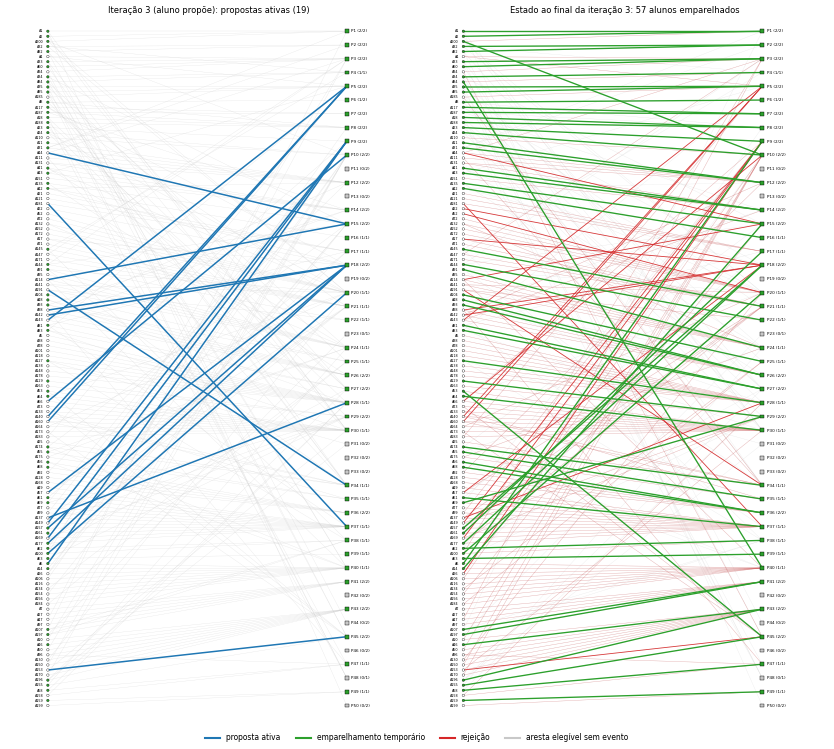


Iteração 4
  Alunos livres no início da iteração: 77
  Fase 1: propostas ativas 1, emparelhamentos temporários novos 0, rejeições 1
    Propostas: A26 propôs a P15
    Rejeições: A26 e P15
  Fase 2: não executada, a fase 1 ainda tinha propostas a fazer
  Ao final da iteração: 57 alunos emparelhados em 38 projetos


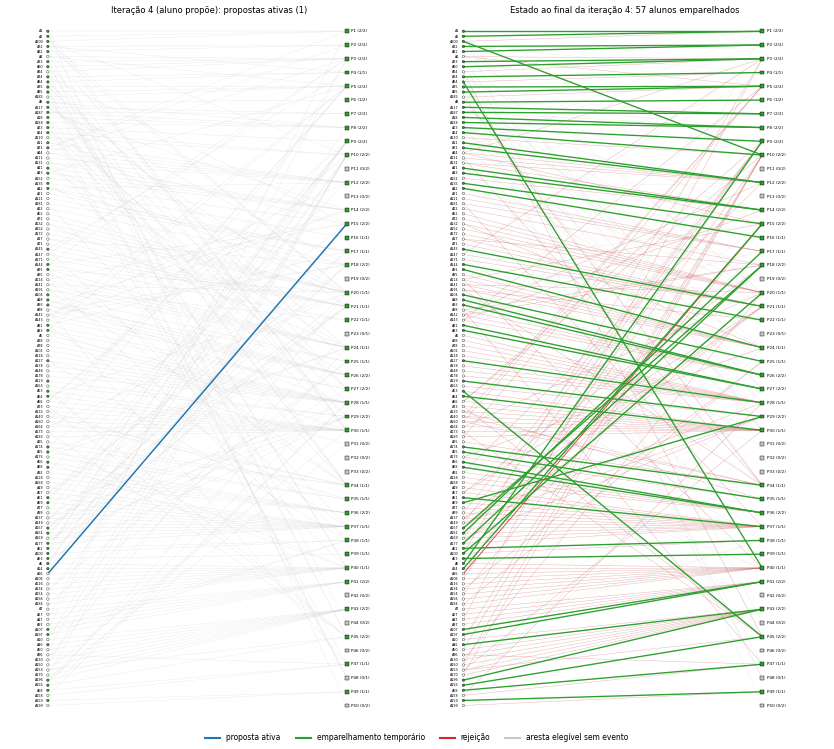


Iteração 5
  Alunos livres no início da iteração: 77
  Fase 1: propostas ativas 0, emparelhamentos temporários novos 0, rejeições 0
  Fase 2: caminho aumentante com 2 alunos: A137 entra em P28; A127 sai de P28 e entra em P31
  Ao final da iteração: 58 alunos emparelhados em 39 projetos


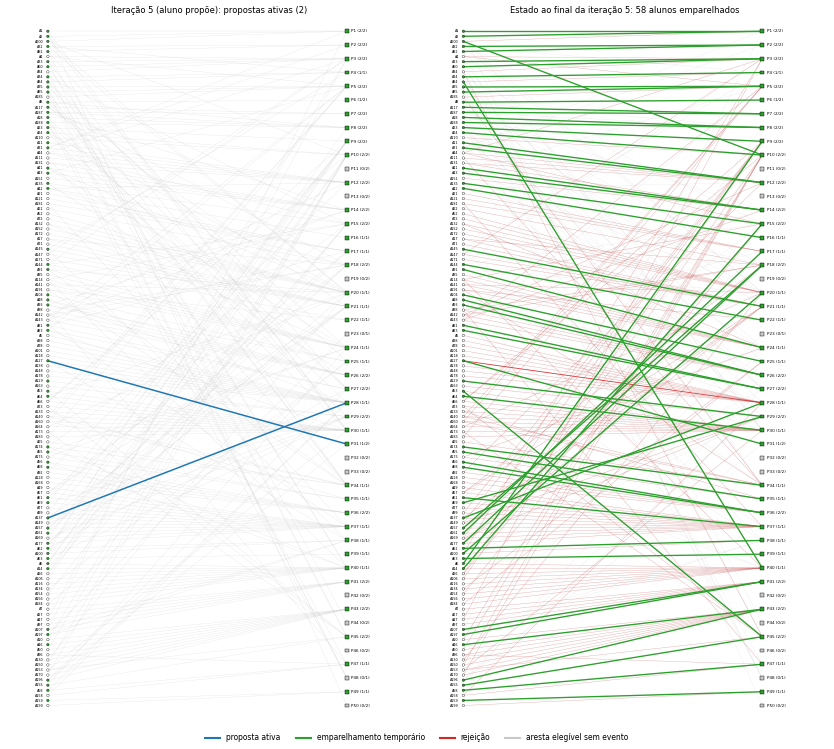


Iteração 6
  Alunos livres no início da iteração: 76
  Fase 1: propostas ativas 0, emparelhamentos temporários novos 0, rejeições 0
  Fase 2: caminho aumentante com 3 alunos: A10 entra em P10; A200 sai de P10 e entra em P1; A1 sai de P1 e entra em P50
  Ao final da iteração: 59 alunos emparelhados em 40 projetos


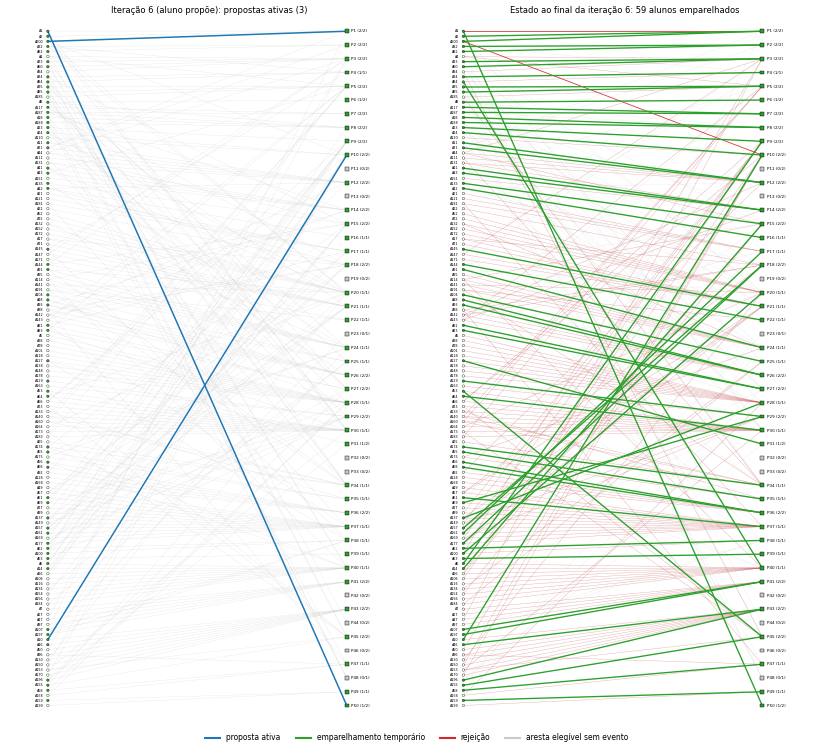


Iteração 7
  Alunos livres no início da iteração: 75
  Fase 1: propostas ativas 0, emparelhamentos temporários novos 0, rejeições 0
  Fase 2: caminho aumentante com 4 alunos: A52 entra em P20; A100 sai de P20 e entra em P38; A62 sai de P38 e entra em P8; A188 sai de P8 e entra em P48
  Ao final da iteração: 60 alunos emparelhados em 41 projetos


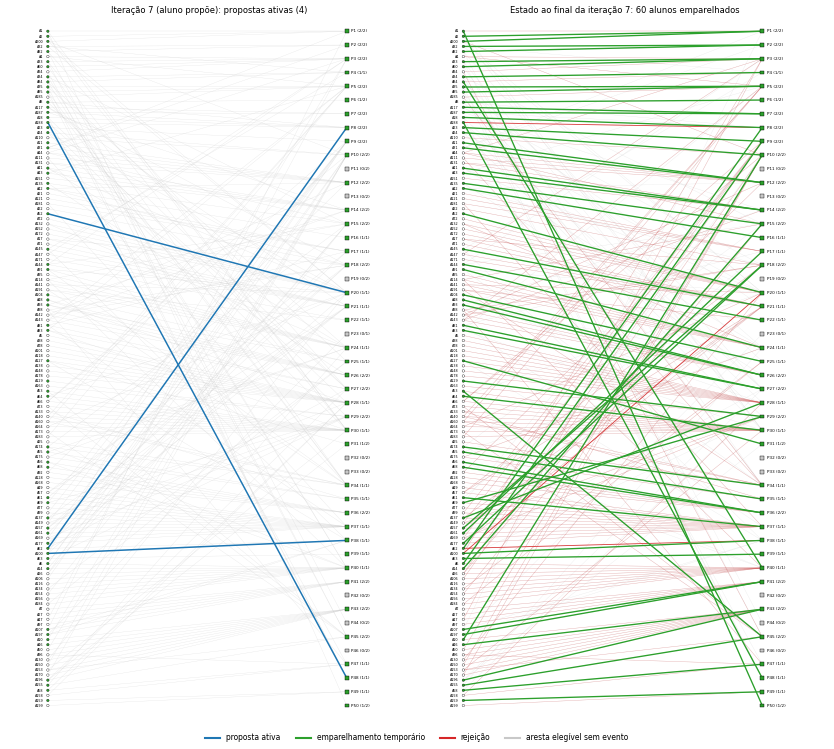


Iteração 8
  Alunos livres no início da iteração: 74
  Fase 1: propostas ativas 0, emparelhamentos temporários novos 0, rejeições 0
  Fase 2: nenhum caminho aumentante estável a partir dos 74 alunos livres
  Ao final da iteração: 60 alunos emparelhados em 41 projetos


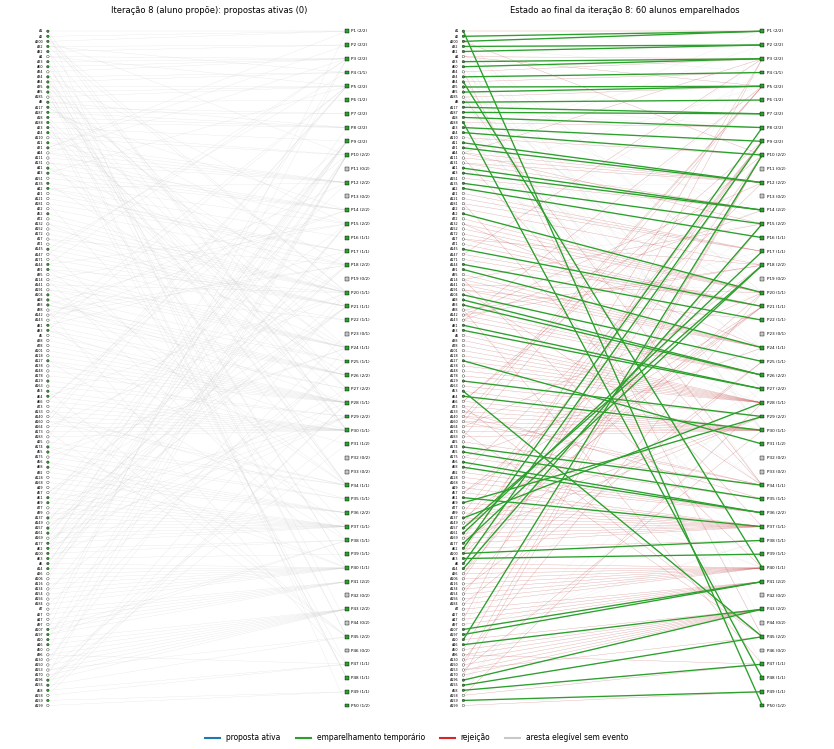


Iteração 9
  Alunos livres no início da iteração: 74
  Fase 1: propostas ativas 0, emparelhamentos temporários novos 0, rejeições 0
  Fase 2: nenhum caminho aumentante estável a partir dos 74 alunos livres
  Ao final da iteração: 60 alunos emparelhados em 41 projetos


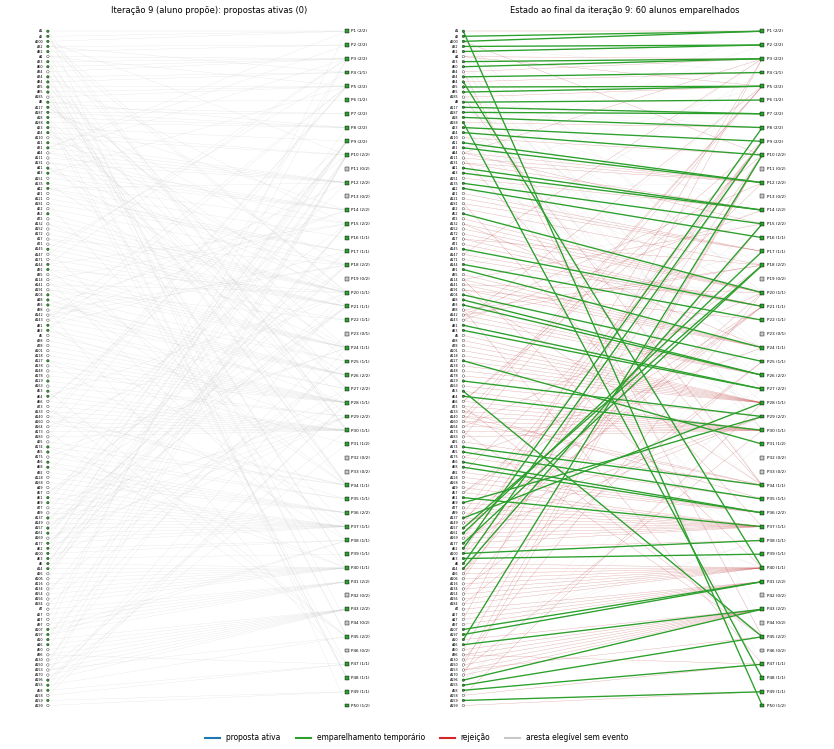


Iteração 10
  Alunos livres no início da iteração: 74
  Fase 1: propostas ativas 0, emparelhamentos temporários novos 0, rejeições 0
  Fase 2: nenhum caminho aumentante estável a partir dos 74 alunos livres
  Ao final da iteração: 60 alunos emparelhados em 41 projetos


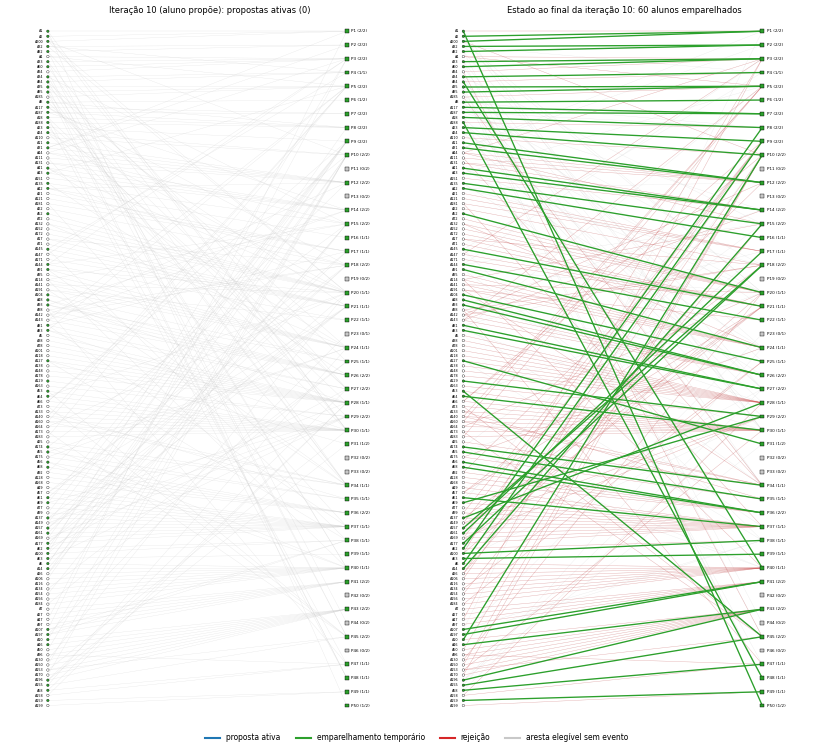


Evolução do emparelhamento (aluno propõe):


,Iteração,Propostas,Rejeições,Caminho aumentante (alunos),Alunos emparelhados,Projetos com aluno
0,1,134,81,0,53,38
1,2,53,49,0,57,38
2,3,19,19,0,57,38
3,4,1,1,0,57,38
4,5,0,0,2,58,39
5,6,0,0,3,59,40
6,7,0,0,4,60,41
7,8,0,0,0,60,41
8,9,0,0,0,60,41
9,10,0,0,0,60,41


Laço estacionário ao final das iterações: True


In [8]:
resaluno = executaremostrar(I, 'aluno')
print('Evolução do emparelhamento (aluno propõe):')
display(tabelaevolucao(resaluno))
print('Laço estacionário ao final das iterações:', resaluno['convergiu'])

## **Etapa 7.** Simulação B: o projeto propõe (proposta final)

Esta é a versão orientada ao projeto (lecturer-oriented). Os projetos propõem aos alunos na ordem da sua lista de preferência, e a fase 1 devolve a alocação estável mais favorável aos projetos. Como pede o enunciado, esta é a proposta final, e a matriz de emparelhamento das próximas etapas sai dela.

Iteração 1
  Alunos livres no início da iteração: 134
  Fase 1: propostas ativas 63, emparelhamentos temporários novos 44, rejeições 19
    Rejeições: A1 e P50; A18 e P47; A23 e P29; A32 e P20; A33 e P45; A34 e P15; A34 e P40; A35 e P24; A35 e P48; A60 e P34; A61 e P17; A63 e P29; A82 e P44; A117 e P18; A127 e P31; A144 e P15; A187 e P14; A196 e P31; A197 e P23
  Fase 2: não executada, a fase 1 ainda tinha propostas a fazer
  Ao final da iteração: 44 alunos emparelhados em 30 projetos


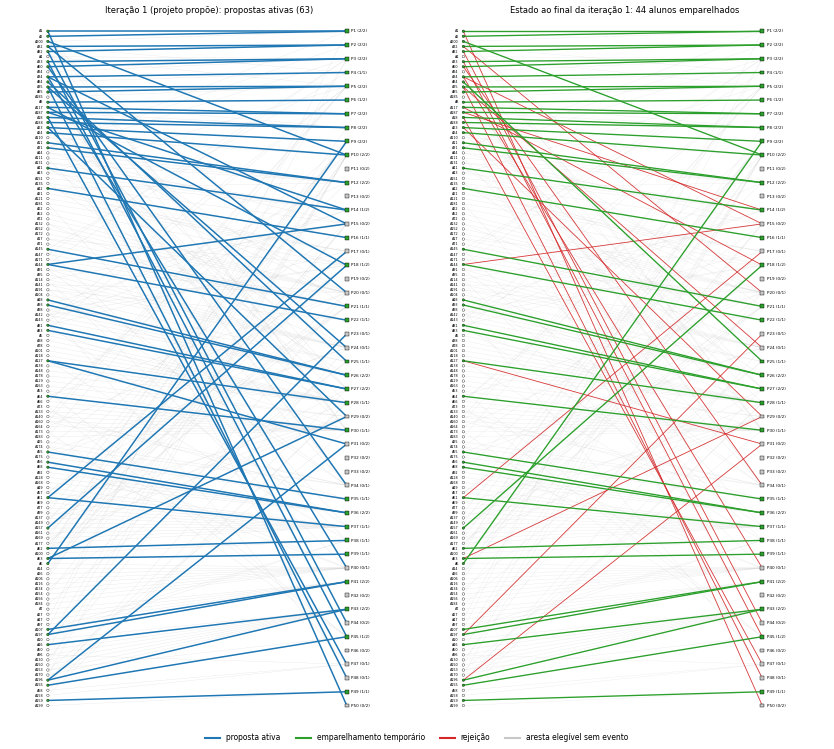


Iteração 2
  Alunos livres no início da iteração: 90
  Fase 1: propostas ativas 14, emparelhamentos temporários novos 10, rejeições 5
    Propostas: P14 propôs a A43; P15 propôs a A135; P15 propôs a A14; P17 propôs a A81; P18 propôs a A177; P20 propôs a A64; P24 propôs a A91; P29 propôs a A69; P29 propôs a A129; P34 propôs a A85; P40 propôs a A84; P45 propôs a A53; P47 propôs a A58; P48 propôs a A85
    Rejeições: A64 e P20; A81 e P17; A84 e P25; A85 e P34; A85 e P48
  Fase 2: não executada, a fase 1 ainda tinha propostas a fazer
  Ao final da iteração: 53 alunos emparelhados em 34 projetos


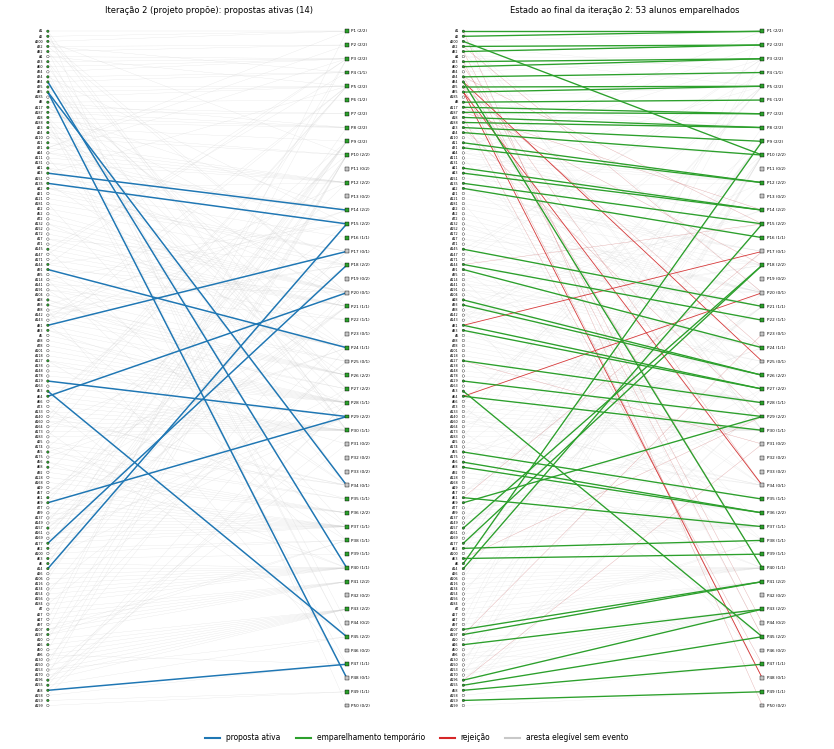


Iteração 3
  Alunos livres no início da iteração: 81
  Fase 1: propostas ativas 5, emparelhamentos temporários novos 3, rejeições 2
    Propostas: P17 propôs a A161; P20 propôs a A100; P25 propôs a A93; P34 propôs a A174; P48 propôs a A188
    Rejeições: A93 e P25; A188 e P48
  Fase 2: não executada, a fase 1 ainda tinha propostas a fazer
  Ao final da iteração: 56 alunos emparelhados em 37 projetos


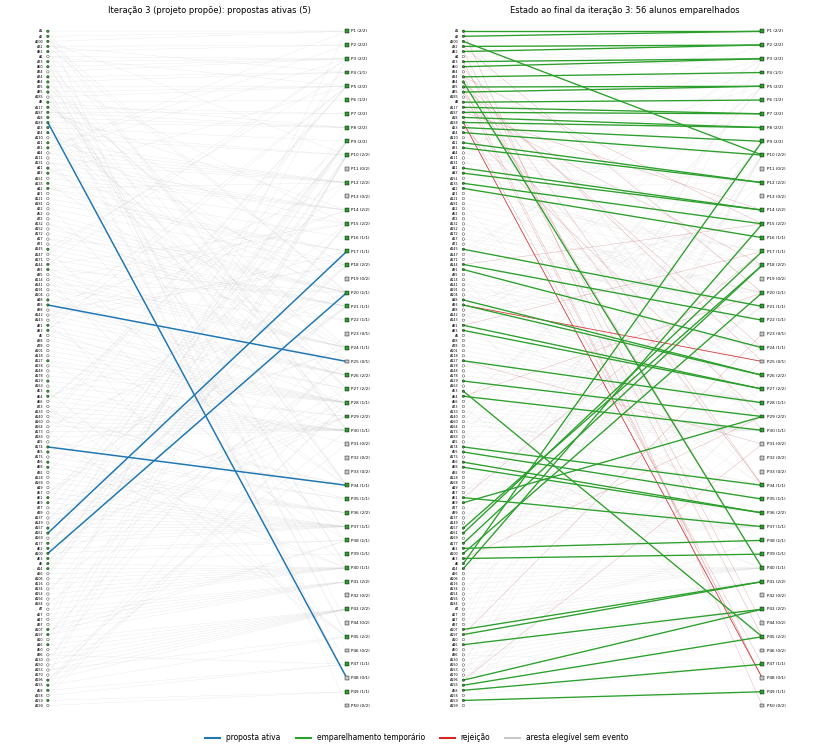


Iteração 4
  Alunos livres no início da iteração: 78
  Fase 1: propostas ativas 1, emparelhamentos temporários novos 1, rejeições 0
    Propostas: P25 propôs a A104
  Fase 2: não executada, a fase 1 ainda tinha propostas a fazer
  Ao final da iteração: 57 alunos emparelhados em 38 projetos


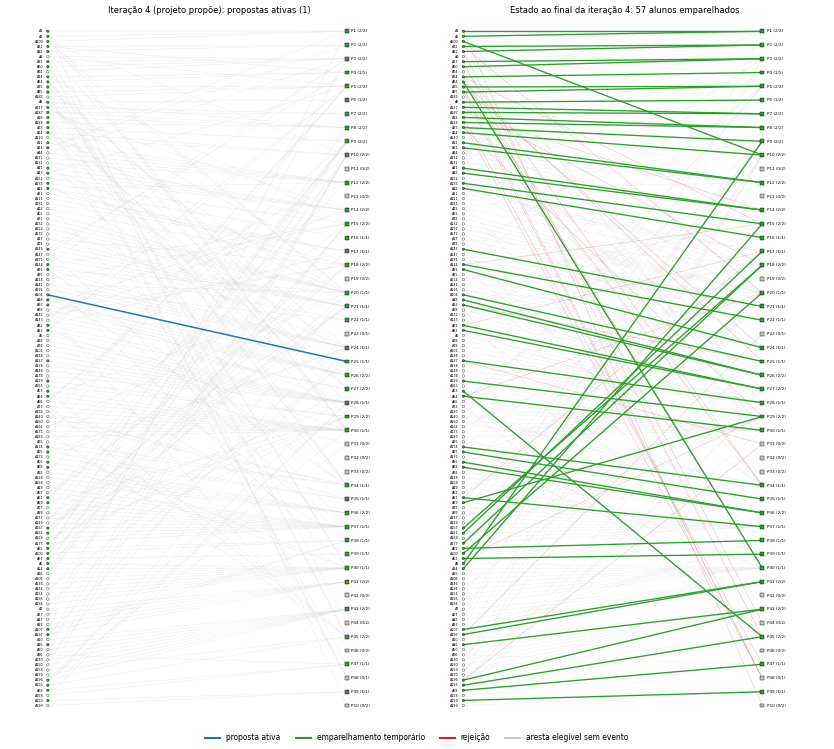


Iteração 5
  Alunos livres no início da iteração: 77
  Fase 1: propostas ativas 0, emparelhamentos temporários novos 0, rejeições 0
  Fase 2: caminho aumentante com 2 alunos: A137 entra em P28; A127 sai de P28 e entra em P31
  Ao final da iteração: 58 alunos emparelhados em 39 projetos


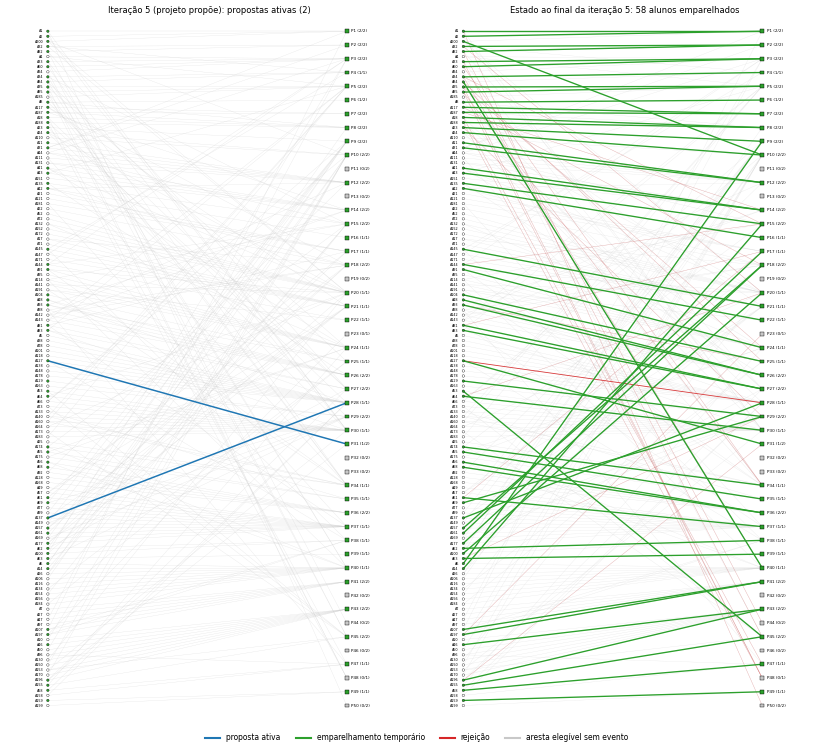


Iteração 6
  Alunos livres no início da iteração: 76
  Fase 1: propostas ativas 0, emparelhamentos temporários novos 0, rejeições 0
  Fase 2: caminho aumentante com 3 alunos: A10 entra em P10; A200 sai de P10 e entra em P1; A1 sai de P1 e entra em P50
  Ao final da iteração: 59 alunos emparelhados em 40 projetos


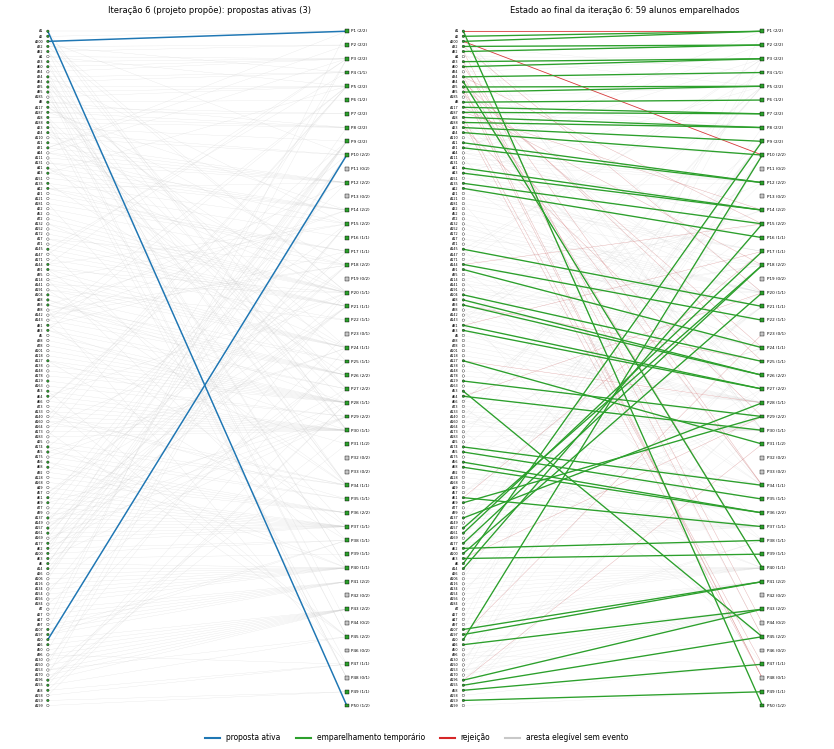


Iteração 7
  Alunos livres no início da iteração: 75
  Fase 1: propostas ativas 0, emparelhamentos temporários novos 0, rejeições 0
  Fase 2: caminho aumentante com 4 alunos: A52 entra em P20; A100 sai de P20 e entra em P38; A62 sai de P38 e entra em P8; A188 sai de P8 e entra em P48
  Ao final da iteração: 60 alunos emparelhados em 41 projetos


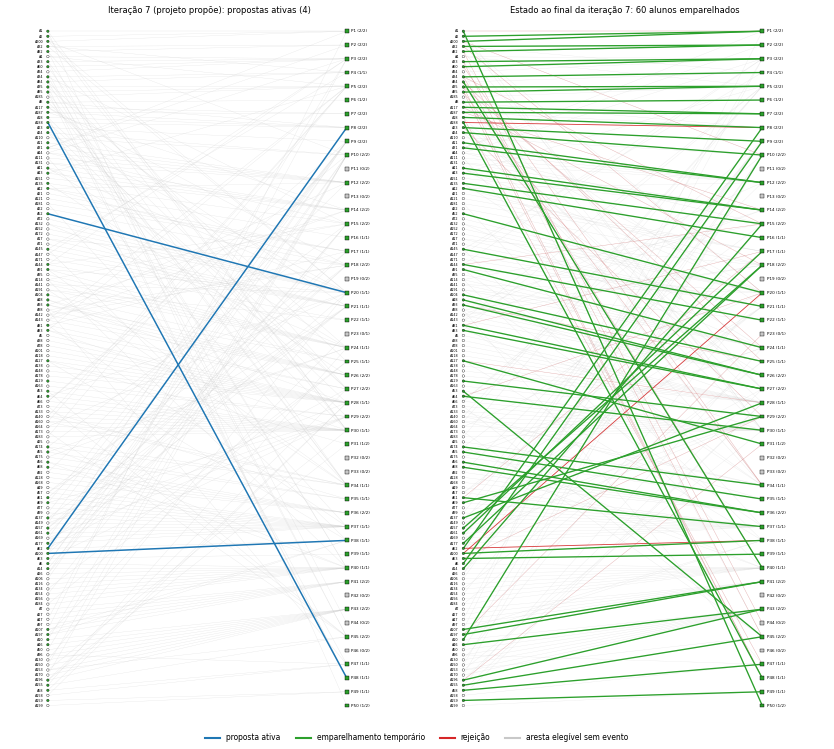


Iteração 8
  Alunos livres no início da iteração: 74
  Fase 1: propostas ativas 0, emparelhamentos temporários novos 0, rejeições 0
  Fase 2: nenhum caminho aumentante estável a partir dos 74 alunos livres
  Ao final da iteração: 60 alunos emparelhados em 41 projetos


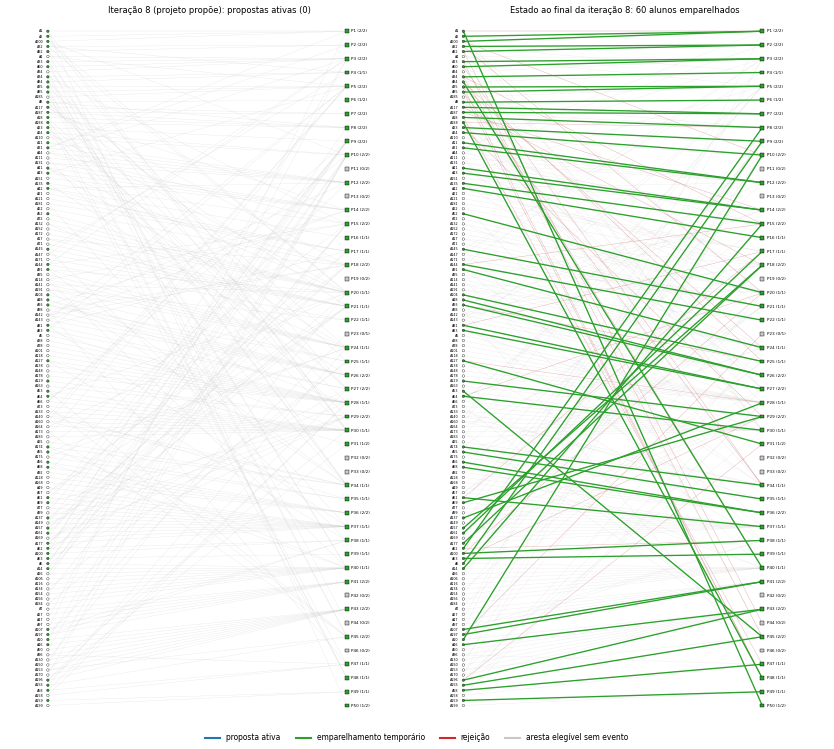


Iteração 9
  Alunos livres no início da iteração: 74
  Fase 1: propostas ativas 0, emparelhamentos temporários novos 0, rejeições 0
  Fase 2: nenhum caminho aumentante estável a partir dos 74 alunos livres
  Ao final da iteração: 60 alunos emparelhados em 41 projetos


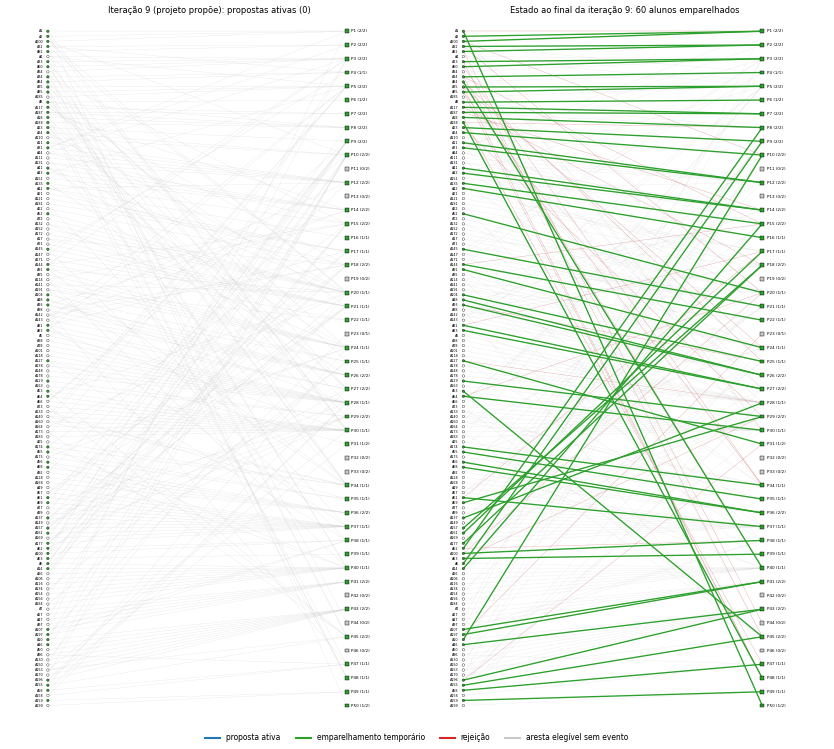


Iteração 10
  Alunos livres no início da iteração: 74
  Fase 1: propostas ativas 0, emparelhamentos temporários novos 0, rejeições 0
  Fase 2: nenhum caminho aumentante estável a partir dos 74 alunos livres
  Ao final da iteração: 60 alunos emparelhados em 41 projetos


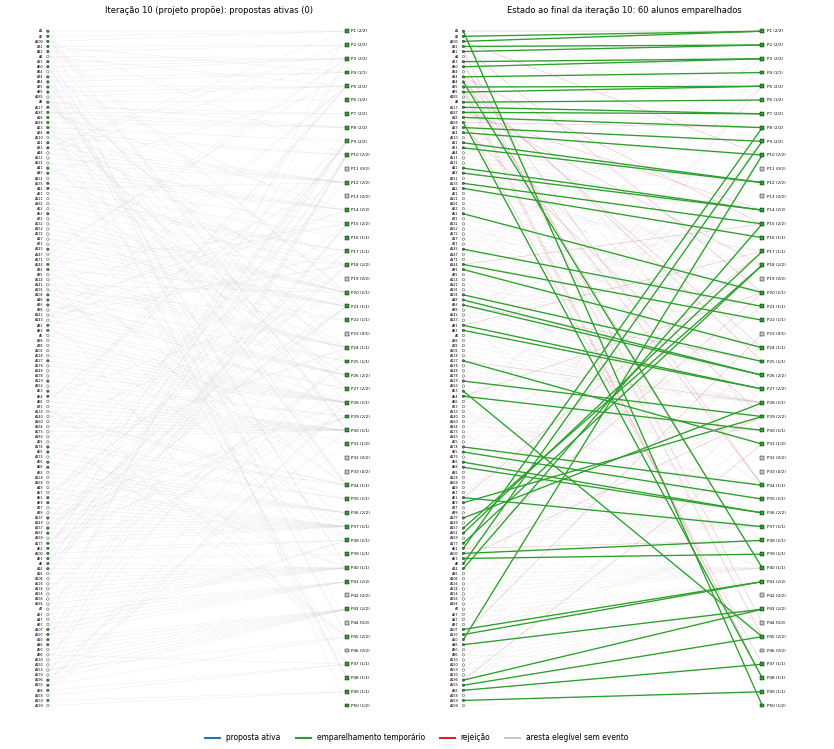


Evolução do emparelhamento (projeto propõe):


,Iteração,Propostas,Rejeições,Caminho aumentante (alunos),Alunos emparelhados,Projetos com aluno
0,1,63,19,0,44,30
1,2,14,5,0,53,34
2,3,5,2,0,56,37
3,4,1,0,0,57,38
4,5,0,0,2,58,39
5,6,0,0,3,59,40
6,7,0,0,4,60,41
7,8,0,0,0,60,41
8,9,0,0,0,60,41
9,10,0,0,0,60,41


Laço estacionário ao final das iterações: True


In [9]:
resprojeto = executaremostrar(I, 'projeto')
print('Evolução do emparelhamento (projeto propõe):')
display(tabelaevolucao(resprojeto))
print('Laço estacionário ao final das iterações:', resprojeto['convergiu'])

## **Etapa 8.** Verificação de estabilidade e comparação das duas simulações

Aqui conferimos o que o algoritmo prometeu. Para cada resultado contamos os pares bloqueantes nos dois sentidos de estabilidade e verificamos que nenhum projeto passou da capacidade e que nenhum aluno foi alocado em projeto fora da sua lista elegível.

Os resultados são comparados em dois momentos: no fim da fase 1 (aceitação adiada pura, estável no sentido estrito) e no fim do laço (depois dos caminhos aumentantes, estável no sentido fraco). Pode haver pares bloqueantes no sentido estrito depois da fase 2. Isso é esperado e acontece só entre alunos de mesma nota, em que o desempate da lista estrita prefere um e o caminho aumentante escolheu o outro. A coluna de pares fracos tem de ser zero.

,alunos,projetos com aluno,respeita vagas,só projetos da lista,pares bloqueantes estritos,pares bloqueantes fracos,1ª escolha,2ª escolha,3ª escolha,posição relativa média na lista do projeto
"Aluno propõe, fim da fase 1",57,38,True,True,0,0,42,8,7,0.331
"Aluno propõe, fim do laço",60,41,True,True,4,0,40,9,11,0.384
"Projeto propõe, fim da fase 1",57,38,True,True,0,0,42,8,7,0.331
"Projeto propõe, fim do laço",60,41,True,True,4,0,40,9,11,0.384


Pares bloqueantes estritos que sobram no fim do laço (proposta final):
  A1 (nota 5) e P1 (alunos de P1 com notas [5, 5]): empate de nota com o pior aluno, não é bloqueio fraco
  A62 (nota 5) e P38 (alunos de P38 com notas [5]): empate de nota com o pior aluno, não é bloqueio fraco
  A127 (nota 5) e P28 (alunos de P28 com notas [5]): empate de nota com o pior aluno, não é bloqueio fraco
  A188 (nota 5) e P8 (alunos de P8 com notas [5, 5]): empate de nota com o pior aluno, não é bloqueio fraco
As duas versões coincidem no fim da fase 1? True
As duas versões coincidem no fim do laço? True
Alunos que recebem projeto diferente nas duas versões: nenhum


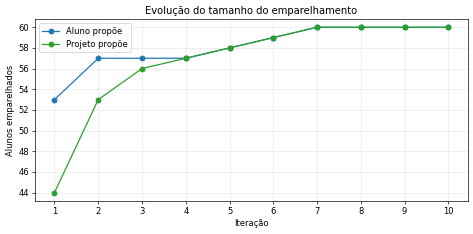

In [10]:
def verificar(I, par):
    cont = Counter(par.values())
    return {'alunos': len(par),
            'projetos com aluno': len(cont),
            'respeita vagas': all(cont[p] <= I.vagas[p] for p in cont),
            'só projetos da lista': all(p in I.prefs[a] for a, p in par.items()),
            'pares bloqueantes estritos': len(paresbloqueantes(I, par, fraca=False)),
            'pares bloqueantes fracos': len(paresbloqueantes(I, par, fraca=True))}


def estatisticasescolha(I, par):
    ordens = Counter(I.escolha[a][p] for a, p in par.items())
    rel = [I.pos[p][a] / len(I.lista[p]) for a, p in par.items()]
    return {'1ª escolha': ordens[1], '2ª escolha': ordens[2], '3ª escolha': ordens[3],
            'posição relativa média na lista do projeto': round(float(np.mean(rel)), 3)}


linhas = {}
for nome, res in (('Aluno propõe', resaluno), ('Projeto propõe', resprojeto)):
    linhas[f'{nome}, fim da fase 1'] = {**verificar(I, res['parda']), **estatisticasescolha(I, res['parda'])}
    linhas[f'{nome}, fim do laço'] = {**verificar(I, res['par']), **estatisticasescolha(I, res['par'])}
dfcomp = pd.DataFrame(linhas).T
display(dfcomp)

# os pares bloqueantes estritos que sobram depois da fase 2 têm que ser só empates da nota
restantes = paresbloqueantes(I, resprojeto['par'], fraca=False)
if restantes:
    ocupf = ocupantes(resprojeto['par'])
    print('Pares bloqueantes estritos que sobram no fim do laço (proposta final):')
    for a, p in restantes:
        notasp = sorted(I.nota[x] for x in ocupf[p])
        assert I.nota[a] <= min(notasp), 'um par estrito com nota maior seria bloqueio fraco'
        print(f"  A{a} (nota {I.nota[a]}) e P{p} (alunos de P{p} com notas {notasp}): empate de nota com o pior aluno, não é bloqueio fraco")
iguaisda = resaluno['parda'] == resprojeto['parda']
print('As duas versões coincidem no fim da fase 1?', iguaisda)
print('As duas versões coincidem no fim do laço?', resaluno['par'] == resprojeto['par'])
dif = sorted(a for a in set(resaluno['par']) | set(resprojeto['par']) if resaluno['par'].get(a) != resprojeto['par'].get(a))
print('Alunos que recebem projeto diferente nas duas versões:', ', '.join(f'A{a}' for a in dif) if dif else 'nenhum')

if MOSTRARGRAFICOS:
    fig, ax = plt.subplots(figsize=(8, 4))
    for nome, res, cor in (('Aluno propõe', resaluno, CORPROPOSTA), ('Projeto propõe', resprojeto, CORTEMPORARIO)):
        ax.plot([r['t'] for r in res['historico']], [r['tam'] for r in res['historico']], marker='o', label=nome, color=cor)
    ax.set_xlabel('Iteração')
    ax.set_ylabel('Alunos emparelhados')
    ax.set_title('Evolução do tamanho do emparelhamento')
    ax.set_xticks(range(1, NITERACOES + 1))
    ax.legend()
    ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

## **Etapa 9.** Matriz final de emparelhamentos

Para cada aluno alocado mostramos os dois lados do "ganho" ou "perda", como pede o enunciado. A coluna da classificação do aluno diz em que posição o aluno ficou na lista de preferência do projeto e quantos alunos havia nela. A coluna da classificação do projeto diz qual foi a escolha do aluno que levou àquele projeto, na ordem em que o aluno escreveu a lista. Posição 1 em uma coluna e escolha 1 na outra significa que os dois lados ficaram com o melhor que podiam esperar.

A figura seguinte desenha a mesma informação como matriz: cada linha é um aluno alocado e cada coluna é um projeto realizado. O número dentro da célula verde é a ordem de escolha do aluno. As células cinza claro marcam outras arestas elegíveis do aluno que não foram usadas.

,Aluno,Nota,Projeto emparelhado,Classificação do aluno (lista de preferência do projeto),Classificação do projeto (lista de preferência do aluno)
0,A2,5,P1,2º (Top 2 de 5 alunos na lista P1),1º (Primeira escolha do aluno A2)
1,A200,5,P1,3º (Top 3 de 5 alunos na lista P1),1º (Primeira escolha do aluno A200)
2,A32,5,P2,1º (Top 1 de 3 alunos na lista P2),1º (Primeira escolha do aluno A32)
3,A82,5,P2,2º (Top 2 de 3 alunos na lista P2),1º (Primeira escolha do aluno A82)
4,A33,5,P3,1º (Top 1 de 9 alunos na lista P3),1º (Primeira escolha do aluno A33)
5,A60,5,P3,2º (Top 2 de 9 alunos na lista P3),1º (Primeira escolha do aluno A60)
6,A34,5,P4,1º (Top 1 de 4 alunos na lista P4),1º (Primeira escolha do aluno A34)
7,A35,5,P5,1º (Top 1 de 10 alunos na lista P5),1º (Primeira escolha do aluno A35)
8,A85,5,P5,2º (Top 2 de 10 alunos na lista P5),1º (Primeira escolha do aluno A85)
9,A8,5,P6,1º (Top 1 de 1 aluno na lista P6),1º (Primeira escolha do aluno A8)


Alunos alocados na 1ª escolha: 40, na 2ª: 9, na 3ª: 11


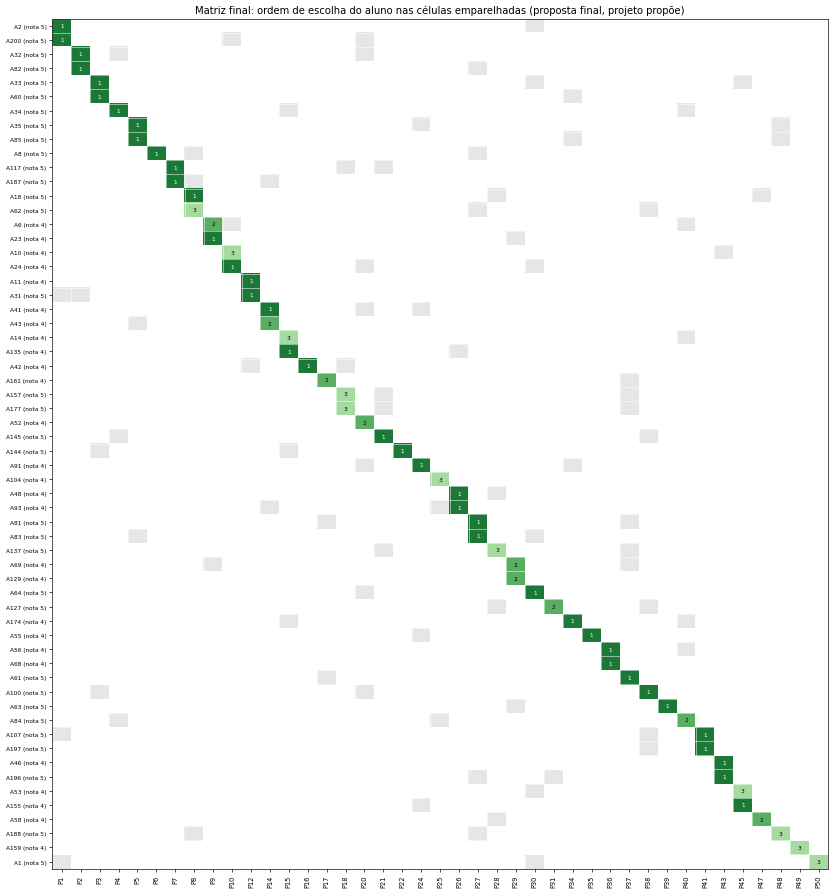

In [11]:
ORDINAL = {1: 'Primeira escolha', 2: 'Segunda escolha', 3: 'Terceira escolha'}


def matrizfinal(I, par):
    linhas = []
    for a in sorted(par, key=lambda a: (par[a], a)):
        p = par[a]
        pos, n, e = I.pos[p][a], len(I.lista[p]), I.escolha[a][p]
        linhas.append({'Aluno': f'A{a}', 'Nota': I.nota[a], 'Projeto emparelhado': f'P{p}',
                       'Classificação do aluno (lista de preferência do projeto)': f"{pos}º (Top {pos} de {n} {'aluno' if n == 1 else 'alunos'} na lista P{p})",
                       'Classificação do projeto (lista de preferência do aluno)': f'{e}º ({ORDINAL[e]} do aluno A{a})'})
    return pd.DataFrame(linhas)


def desenharmatriz(I, par):
    alunosm = sorted(par, key=lambda a: (par[a], a))
    projs = sorted(set(par.values()))
    col = {p: j for j, p in enumerate(projs)}
    M = np.zeros((len(alunosm), len(projs)))
    for i, a in enumerate(alunosm):
        for p in I.prefs[a]:
            if p in col:
                M[i, col[p]] = 4                    # aresta elegível não usada
        M[i, col[par[a]]] = I.escolha[a][par[a]]    # emparelhada: 1, 2 ou 3
    cmap = ListedColormap(['white', '#1b7837', '#5aae61', '#a6dba0', '#e6e6e6'])
    fig, ax = plt.subplots(figsize=(14, 15))
    ax.imshow(M, cmap=cmap, norm=BoundaryNorm([-0.5, 0.5, 1.5, 2.5, 3.5, 4.5], 5), aspect='auto')
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            if 1 <= M[i, j] <= 3:
                ax.text(j, i, int(M[i, j]), ha='center', va='center', color='white' if M[i, j] == 1 else 'black', fontsize=7)
    ax.set_xticks(range(len(projs)))
    ax.set_xticklabels([f'P{p}' for p in projs], rotation=90, fontsize=8)
    ax.set_yticks(range(len(alunosm)))
    ax.set_yticklabels([f'A{a} (nota {I.nota[a]})' for a in alunosm], fontsize=7)
    ax.set_xticks(np.arange(-0.5, len(projs), 1), minor=True)
    ax.set_yticks(np.arange(-0.5, len(alunosm), 1), minor=True)
    ax.grid(which='minor', color='white', linewidth=0.6)
    ax.tick_params(which='minor', length=0)
    ax.set_title('Matriz final: ordem de escolha do aluno nas células emparelhadas (proposta final, projeto propõe)')
    plt.tight_layout()
    plt.show()


parfinal = resprojeto['par']
dfmatriz = matrizfinal(I, parfinal)
display(dfmatriz)
ordens = Counter(I.escolha[a][p] for a, p in parfinal.items())
print(f"Alunos alocados na 1ª escolha: {ordens[1]}, na 2ª: {ordens[2]}, na 3ª: {ordens[3]}")
if MOSTRARGRAFICOS:
    desenharmatriz(I, parfinal)

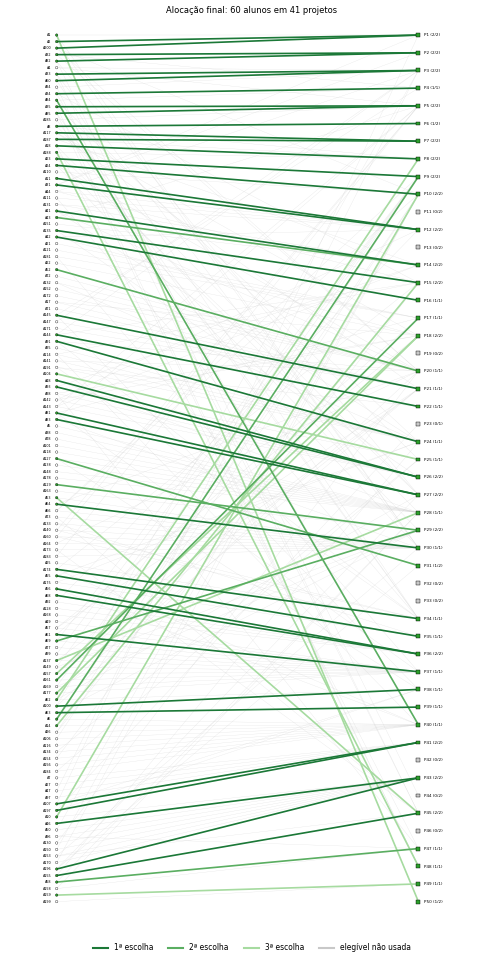

In [12]:
def desenharfinal(I, par):
    """Grafo bipartido da alocação final. Espessura e tom do verde seguem a ordem de escolha do aluno."""
    ys, yp = layoutbipartido(I, I.elegiveis)
    todas = [(a, p) for a in I.elegiveis for p in I.prefs[a]]
    porordem = {k: [(a, p) for a, p in par.items() if I.escolha[a][p] == k] for k in (1, 2, 3)}
    fig, ax = plt.subplots(figsize=(8.5, 16))
    desenharpainel(ax, I, ys, yp, par,
                    [(todas, CORFUNDO, 0.3, 0.6, 'solid'),
                     (porordem[3], '#a6dba0', 2.0, 1.0, 'solid'),
                     (porordem[2], '#5aae61', 2.0, 1.0, 'solid'),
                     (porordem[1], '#1b7837', 2.0, 1.0, 'solid')],
                    f'Alocação final: {len(par)} alunos em {len(set(par.values()))} projetos')
    legenda(fig, [('1ª escolha', '#1b7837', '-'), ('2ª escolha', '#5aae61', '-'),
                  ('3ª escolha', '#a6dba0', '-'), ('elegível não usada', CORFUNDO, '-')], 4)
    plt.tight_layout(rect=(0, 0.03, 1, 1))
    plt.show()


if MOSTRARGRAFICOS:
    desenharfinal(I, parfinal)

## **Etapa 10.** Quem ficou de fora e quais projetos foram realizados

Os alunos sem projeto se dividem em dois grupos. O primeiro é o dos que não têm nenhuma opção elegível, porque todas as suas escolhas foram barradas pela nota ou não existem. O segundo é o dos que tinham opções, mas todos os projetos elegíveis ficaram cheios de alunos com nota igual ou maior. A célula confere automaticamente que, no segundo grupo, é isso mesmo que acontece, o que é a prova de que nenhum deles bloqueia o emparelhamento.

Para os projetos, o critério do enunciado é que cada projeto realizado precisa de pelo menos um aluno.

In [13]:
#codigooo

## **Etapa 11.** Quão bom é o resultado: limite superior e prova de otimalidade

Duas referências mostram se o tamanho obtido é bom.

A primeira é o maior emparelhamento possível ignorando a estabilidade. Ele é um limite superior, e a diferença para o nosso resultado é o preço de exigir estabilidade.

A segunda é a solução exata do problema "maior emparelhamento fracamente estável" por programação linear inteira. Para cada aresta (a, p) existe uma variável binária que vale 1 quando o aluno a é alocado em p. As restrições dizem que cada aluno recebe no máximo um projeto, que cada projeto recebe no máximo suas vagas, e que não há par bloqueante fraco. A restrição de estabilidade para cada aresta (a, p) é

vagas(p) · (soma das variáveis de a em projetos tão bons quanto p ou melhores) + (soma das variáveis em p dos alunos com nota maior ou igual à de a) ≥ vagas(p)

Se a está emparelhado em p ou em algo melhor, o primeiro termo já cobre o lado direito. Se não está, o projeto p precisa estar cheio só de alunos com nota maior ou igual à de a. Maximizar a soma das variáveis dá o tamanho ótimo. Se ele for igual ao que o algoritmo achou, o resultado é comprovadamente máximo.

In [14]:
#codigooo

## Conclusões

**Resultado:**

**Evolução do laço:**

**Quão bom é o resultado:**

**Estabilidade:**

**Sensibilidade ao desempate:**

**o que falta:** o arquivo não traz a preferência dos projetos, então ela foi derivada da nota, com desempate determinístico. ver isso